
# Hospital Readmission Risk Prediction Using MLP

**Industry:** Healthcare  
**Methodology:** CBIM (Business Understanding → Data Preparation → Modeling → Evaluation → Business Insights)  
**Framework:** TensorFlow / Keras (Sequential API)  
**Dataset:** Diabetes 130-US Hospitals (1999–2008)  
**Problem Type:** Supervised Binary Classification

---

## 1. Business Understanding — CBIM Canvas

| CBIM Component | Business Definition |
|---|---|
| **Business Problem** | Hospitals face increased costs, bed occupancy, and care coordination challenges when diabetic patients are readmitted shortly after discharge. |
| **Business Objective** | Identify patients at increased risk of readmission within 30 days to support proactive discharge planning and follow-up care. |
| **Stakeholders** | Hospital administrators, discharge planning teams, care coordinators, and healthcare professionals. |
| **Target Population** | Hospital encounters involving patients with diabetes. |
| **Decision Point** | At hospital discharge, when follow-up care can be planned. |
| **Available Inputs** | Patient demographics, admission details, treatment information, and previous hospital utilization available by discharge. |
| **ML Problem** | Predict the probability of hospital readmission within 30 days using a Multi-Layer Perceptron (MLP). |
| **Target Variable** | `readmitted`: 1 = `<30`; 0 = `>30` or `NO`. |
| **Primary Evaluation Priority** | Recall — reduce false negatives, where patients who are subsequently readmitted are incorrectly classified as low-risk. |
| **Supporting Metrics** | Precision, F1-score, ROC-AUC, PR-AUC, and confusion matrix. |
| **Business Action** | Prioritize higher-risk patients for appropriate discharge support and follow-up review. |
| **Business Constraints** | Class imbalance, missing data, data leakage, limited follow-up resources, and historical dataset limitations. |
| **Expected Deliverable** | Reproducible MLP pipeline, patient-level risk predictions, structured error analysis, and business recommendations. |
| **Success Criteria** | Demonstrate improvement over a baseline, identify a useful recall–precision trade-off, and provide interpretable evaluation and actionable insights. |

### 1.1 Business-to-ML Translation

**Business Question:**  
Which diabetic patient encounters are associated with an increased risk of readmission within 30 days?

**Machine Learning Question:**  
Can an MLP estimate the probability of 30-day readmission from patient and hospital encounter characteristics known at discharge?

**Classification Target:**

- **1 (Positive):** Readmitted within 30 days.
- **0 (Negative):** Readmitted after 30 days or not readmitted.

### 1.2 Business Risk and Error Trade-off

- **False Negative (Type II Error):** A patient who is readmitted within 30 days is predicted as low-risk. This may result in a missed opportunity for additional follow-up.
- **False Positive (Type I Error):** A patient who is not readmitted within 30 days is predicted as high-risk. This may consume unnecessary follow-up resources.

**Modeling Decision:** Prioritize recall while monitoring precision, false-positive volume, and operational feasibility.

### 1.3 Scope and Limitations

This project is an educational proof of concept using historical US hospital encounters from 1999–2008. Predictions are not clinically validated and must not be used as independent medical decisions.


In [3]:

import pandas as pd
from pathlib import Path

# Paths relative to the notebook directory
DATA_DIR = Path("../data/raw")

# Load main dataset
df = pd.read_csv(DATA_DIR / "diabetic_data.csv")

# Load lookup file for initial inspection
mapping_path = DATA_DIR / "IDS_mapping.csv"

print("MAIN DATASET")
print("Shape:", df.shape)

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nFIRST 5 RECORDS:")
display(df.head())

print("\nLOOKUP FILE - FIRST 20 LINES:")
with open(mapping_path, encoding="utf-8-sig") as file:
    for _, line in zip(range(20), file):
        print(line.rstrip())


MAIN DATASET
Shape: (101766, 50)

COLUMN NAMES:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

FIRST 5 RECORDS:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



LOOKUP FILE - FIRST 20 LINES:
admission_type_id,description
1,Emergency
2,Urgent
3,Elective
4,Newborn
5,Not Available
6,NULL
7,Trauma Center
8,Not Mapped
,
discharge_disposition_id,description
1,Discharged to home
2,Discharged/transferred to another short term hospital
3,Discharged/transferred to SNF
4,Discharged/transferred to ICF
5,Discharged/transferred to another type of inpatient care institution
6,Discharged/transferred to home with home health service
7,Left AMA
8,Discharged/transferred to home under care of Home IV provider
9,Admitted as an inpatient to this hospital


In [4]:

# Main dataset structural inspection

print("DATASET SHAPE:")
print(df.shape)

print("\nCOLUMN INFORMATION:")
df.info(verbose=True, show_counts=True)

print("\nDATA TYPES SUMMARY:")
print(df.dtypes.value_counts())



DATASET SHAPE:
(101766, 50)

COLUMN INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non

In [5]:
df.describe()

,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


In [6]:

# Inspect feature values before deciding data types

columns_to_inspect = [
    "age",
    "weight",
    "time_in_hospital",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "max_glu_serum",
    "A1Cresult",
    "readmitted"
]

for col in columns_to_inspect:
    print(f"\n{'=' * 55}")
    print(f"FEATURE: {col}")
    print(f"DATA TYPE: {df[col].dtype}")
    print(f"UNIQUE VALUES: {df[col].nunique(dropna=False)}")
    print("VALUE DISTRIBUTION:")
    print(df[col].value_counts(dropna=False).to_string())



FEATURE: age
DATA TYPE: str
UNIQUE VALUES: 10
VALUE DISTRIBUTION:
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161

FEATURE: weight
DATA TYPE: str
UNIQUE VALUES: 10
VALUE DISTRIBUTION:
weight
?            98569
[75-100)      1336
[50-75)        897
[100-125)      625
[125-150)      145
[25-50)         97
[0-25)          48
[150-175)       35
[175-200)       11
>200             3

FEATURE: time_in_hospital
DATA TYPE: int64
UNIQUE VALUES: 14
VALUE DISTRIBUTION:
time_in_hospital
3     17756
2     17224
1     14208
4     13924
5      9966
6      7539
7      5859
8      4391
9      3002
10     2342
11     1855
12     1448
13     1210
14     1042

FEATURE: admission_type_id
DATA TYPE: int64
UNIQUE VALUES: 8
VALUE DISTRIBUTION:
admission_type_id
1    53990
3    18869
2    18480
6     5291
5     4785
8      320
7       21
4       10

FEATURE: discharge_disposi

In [7]:

import pandas as pd

# Work on a copy — preserve original data
audit_df = df.copy()

string_cols = audit_df.select_dtypes(
    include=["object", "str", "string"]
).columns

placeholders = {
    "?", "null", "none", "nan", "na",
    "n/a", "missing", "unknown",
    "not available", "not mapped"
}

audit_results = []

for col in string_cols:
    s = audit_df[col].astype("string")
    stripped = s.str.strip()
    normalized = stripped.str.lower()

    audit_results.append({
        "column": col,
        "actual_nulls": s.isna().sum(),
        "placeholder_count": normalized.isin(placeholders).sum(),
        "leading_trailing_spaces": (
            s.ne(stripped).fillna(False).sum()
        ),
        "empty_or_spaces_only": (
            stripped.eq("").fillna(False).sum()
        ),
        "case_variations": (
            s.dropna().nunique()
            - normalized.dropna().nunique()
        )
    })

audit_report = pd.DataFrame(audit_results)

print("STRING DATA QUALITY AUDIT")
print(
    audit_report.to_string(index=False)
)


STRING DATA QUALITY AUDIT
                  column  actual_nulls  placeholder_count  leading_trailing_spaces  empty_or_spaces_only  case_variations
                    race             0               2273                        0                     0                0
                  gender             0                  0                        0                     0                0
                     age             0                  0                        0                     0                0
                  weight             0              98569                        0                     0                0
              payer_code             0              40256                        0                     0                0
       medical_specialty             0              49949                        0                     0                0
                  diag_1             0                 21                        0                     0                

In [8]:

import pandas as pd
import numpy as np

# Select only numerical columns
numeric_cols = df.select_dtypes(include="number").columns

numerical_audit = []

for col in numeric_cols:
    s = df[col]

    numerical_audit.append({
        "column": col,
        "dtype": str(s.dtype),
        "null_count": s.isna().sum(),
        "unique_values": s.nunique(),
        "min_value": s.min(),
        "max_value": s.max(),
        "zero_count": s.eq(0).sum(),
        "negative_count": s.lt(0).sum(),
        "infinite_count": np.isinf(s).sum()
    })

numerical_audit_df = pd.DataFrame(numerical_audit)

print("NUMERICAL DATA QUALITY AUDIT")
print(numerical_audit_df.to_string(index=False))


NUMERICAL DATA QUALITY AUDIT
                  column dtype  null_count  unique_values  min_value  max_value  zero_count  negative_count  infinite_count
            encounter_id int64           0         101766      12522  443867222           0               0               0
             patient_nbr int64           0          71518        135  189502619           0               0               0
       admission_type_id int64           0              8          1          8           0               0               0
discharge_disposition_id int64           0             26          1         28           0               0               0
     admission_source_id int64           0             17          1         25           0               0               0
        time_in_hospital int64           0             14          1         14           0               0               0
      num_lab_procedures int64           0            118          1        132           0            

In [9]:

# Step 5: Duplicate and repeated patient analysis

print("Total encounters:", len(df))

print("\n1. EXACT DUPLICATE ROWS")
print("Duplicate rows:", df.duplicated().sum())

print("\n2. DUPLICATE ENCOUNTER IDs")
print(
    "Duplicate encounter IDs:",
    df["encounter_id"].duplicated().sum()
)

print("\n3. PATIENT-LEVEL ANALYSIS")

patient_visits = df["patient_nbr"].value_counts()

print("Unique patients:", df["patient_nbr"].nunique())
print("Patients with multiple encounters:", (patient_visits > 1).sum())
print("Maximum encounters for one patient:", patient_visits.max())

print("\n4. ENCOUNTERS PER PATIENT DISTRIBUTION")
print(
    patient_visits.value_counts()
    .sort_index()
    .to_string()
)

print("\n5. SAMPLE REPEATED PATIENT ENCOUNTERS")

repeated_ids = patient_visits[patient_visits > 1].index[:5]

display(
    df.loc[
        df["patient_nbr"].isin(repeated_ids),
        [
            "patient_nbr",
            "encounter_id",
            "age",
            "time_in_hospital",
            "number_inpatient",
            "readmitted"
        ]
    ].sort_values(["patient_nbr", "encounter_id"])
)


Total encounters: 101766

1. EXACT DUPLICATE ROWS
Duplicate rows: 0

2. DUPLICATE ENCOUNTER IDs
Duplicate encounter IDs: 0

3. PATIENT-LEVEL ANALYSIS
Unique patients: 71518
Patients with multiple encounters: 16773
Maximum encounters for one patient: 40

4. ENCOUNTERS PER PATIENT DISTRIBUTION
count
1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
11       20
12       19
13       14
14        5
15        9
16        4
17        3
18        6
19        3
20        6
21        1
22        2
23        3
28        1
40        1

5. SAMPLE REPEATED PATIENT ENCOUNTERS


,patient_nbr,encounter_id,age,time_in_hospital,number_inpatient,readmitted
269,1660293,2967810,[60-70),10,0,>30
944,1660293,7216812,[60-70),4,1,<30
1077,1660293,7977342,[60-70),12,2,<30
1349,1660293,9358128,[60-70),8,3,>30
2954,1660293,18844260,[60-70),3,4,>30
...,...,...,...,...,...,...
91444,88785891,309563132,[20-30),3,12,<30
97433,88785891,388509176,[20-30),5,8,<30
97732,88785891,392073212,[20-30),3,10,>30
99950,88785891,419611106,[20-30),2,12,>30


In [10]:

# Investigate unusually frequent hospital encounters

high_frequency = patient_visits[
    patient_visits >= 10
]

print("Patients with 10+ encounters:", len(high_frequency))

print("\nTOP 10 PATIENTS BY ENCOUNTER COUNT:")
print(high_frequency.head(10).to_string())

top_patient = patient_visits.idxmax()

print(f"\nPATIENT WITH MOST ENCOUNTERS: {top_patient}")

display(
    df.loc[
        df["patient_nbr"] == top_patient,
        [
            "encounter_id",
            "age",
            "time_in_hospital",
            "number_inpatient",
            "number_emergency",
            "readmitted"
        ]
    ].sort_values("encounter_id")
)


Patients with 10+ encounters: 139

TOP 10 PATIENTS BY ENCOUNTER COUNT:
patient_nbr
88785891    40
43140906    28
1660293     23
23199021    23
88227540    23
23643405    22
84428613    22
92709351    21
90609804    20
89472402    20

PATIENT WITH MOST ENCOUNTERS: 88785891


,encounter_id,age,time_in_hospital,number_inpatient,number_emergency,readmitted
38307,119039172,[20-30),1,0,0,>30
40252,125094312,[20-30),1,2,0,<30
40661,126171582,[20-30),5,3,0,>30
44515,137245596,[20-30),2,5,0,<30
45147,139425576,[20-30),2,6,0,<30
45986,141994242,[20-30),4,7,0,<30
50167,150986298,[20-30),1,9,1,<30
50393,151413846,[20-30),4,9,1,<30
50773,152188656,[20-30),1,10,1,<30
51519,153558456,[20-30),1,11,1,<30


In [11]:

# Inspect complete mapping file with line numbers

with open(mapping_path, encoding="utf-8-sig") as file:
    for line_number, line in enumerate(file, start=1):
        print(f"{line_number:3}: {line.rstrip()}")


  1: admission_type_id,description
  2: 1,Emergency
  3: 2,Urgent
  4: 3,Elective
  5: 4,Newborn
  6: 5,Not Available
  7: 6,NULL
  8: 7,Trauma Center
  9: 8,Not Mapped
 10: ,
 11: discharge_disposition_id,description
 12: 1,Discharged to home
 13: 2,Discharged/transferred to another short term hospital
 14: 3,Discharged/transferred to SNF
 15: 4,Discharged/transferred to ICF
 16: 5,Discharged/transferred to another type of inpatient care institution
 17: 6,Discharged/transferred to home with home health service
 18: 7,Left AMA
 19: 8,Discharged/transferred to home under care of Home IV provider
 20: 9,Admitted as an inpatient to this hospital
 21: 10,Neonate discharged to another hospital for neonatal aftercare
 22: 11,Expired
 23: 12,Still patient or expected to return for outpatient services
 24: 13,Hospice / home
 25: 14,Hospice / medical facility
 26: 15,Discharged/transferred within this institution to Medicare approved swing bed
 27: 16,Discharged/transferred/referred another in

In [12]:

import csv
import pandas as pd

# Parse the three logical lookup tables
mapping_tables = {}
current_table = None

with open(mapping_path, encoding="utf-8-sig", newline="") as file:
    reader = csv.reader(file)

    for row in reader:
        if not row or not row[0].strip():
            continue

        if row[0].strip().endswith("_id"):
            current_table = row[0].strip()
            mapping_tables[current_table] = {}
            continue

        if current_table is not None:
            mapping_tables[current_table][int(row[0])] = row[1].strip()

# Verify foreign-key coverage
for col, mapping in mapping_tables.items():
    dataset_ids = set(df[col].dropna().unique())
    mapped_ids = set(mapping.keys())

    print(f"\n{'=' * 55}")
    print(f"FEATURE: {col}")
    print(f"Dataset unique IDs: {len(dataset_ids)}")
    print(f"Mapping unique IDs: {len(mapped_ids)}")
    print(f"Unmapped IDs in dataset: {dataset_ids - mapped_ids}")
    print(f"Unused IDs in mapping: {mapped_ids - dataset_ids}")
    print(f"All dataset IDs mapped: {dataset_ids <= mapped_ids}")



FEATURE: admission_type_id
Dataset unique IDs: 8
Mapping unique IDs: 8
Unmapped IDs in dataset: set()
Unused IDs in mapping: set()
All dataset IDs mapped: True

FEATURE: discharge_disposition_id
Dataset unique IDs: 26
Mapping unique IDs: 30
Unmapped IDs in dataset: set()
Unused IDs in mapping: {26, 29, 21, 30}
All dataset IDs mapped: True

FEATURE: admission_source_id
Dataset unique IDs: 17
Mapping unique IDs: 25
Unmapped IDs in dataset: set()
Unused IDs in mapping: {12, 15, 18, 19, 21, 23, 24, 26}
All dataset IDs mapped: True


In [13]:

# Discharge disposition eligibility inspection

discharge_mapping = mapping_tables["discharge_disposition_id"]

discharge_audit = (
    df["discharge_disposition_id"]
    .value_counts()
    .rename_axis("discharge_disposition_id")
    .reset_index(name="encounter_count")
)

discharge_audit["description"] = (
    discharge_audit["discharge_disposition_id"]
    .map(discharge_mapping)
)

discharge_audit["percentage"] = (
    discharge_audit["encounter_count"] / len(df) * 100
).round(2)

discharge_audit = discharge_audit[
    [
        "discharge_disposition_id",
        "description",
        "encounter_count",
        "percentage"
    ]
].sort_values("encounter_count", ascending=False)

print("DISCHARGE DISPOSITION AUDIT")
print(discharge_audit.to_string(index=False))


DISCHARGE DISPOSITION AUDIT
 discharge_disposition_id                                                                                               description  encounter_count  percentage
                        1                                                                                        Discharged to home            60234       59.19
                        3                                                                             Discharged/transferred to SNF            13954       13.71
                        6                                                   Discharged/transferred to home with home health service            12902       12.68
                       18                                                                                                      NULL             3691        3.63
                        2                                                     Discharged/transferred to another short term hospital             2128        2.09
      

In [14]:

# Analyze readmission labels for death-related discharges

expired_ids = [11, 19, 20, 21]

expired_df = df[
    df["discharge_disposition_id"].isin(expired_ids)
]

print("Death-related discharge encounters:", len(expired_df))

print("\nREADMISSION TARGET DISTRIBUTION:")
print(expired_df["readmitted"].value_counts(dropna=False))

print("\nTARGET DISTRIBUTION BY DISCHARGE ID:")
print(
    pd.crosstab(
        expired_df["discharge_disposition_id"],
        expired_df["readmitted"]
    ).to_string()
)

print("\nPERCENTAGE OF TOTAL DATASET:")
print(f"{len(expired_df) / len(df) * 100:.2f}%")


Death-related discharge encounters: 1652

READMISSION TARGET DISTRIBUTION:
readmitted
NO    1652
Name: count, dtype: int64

TARGET DISTRIBUTION BY DISCHARGE ID:
readmitted                  NO
discharge_disposition_id      
11                        1642
19                           8
20                           2

PERCENTAGE OF TOTAL DATASET:
1.62%


In [15]:

# Define death-related discharge codes
DEATH_RELATED_IDS = {11, 19, 20, 21}

# Preserve original df; create eligible cohort
df_eligible = df.loc[
    ~df["discharge_disposition_id"].isin(DEATH_RELATED_IDS)
].copy()

print("Original encounters:", len(df))
print("Excluded encounters:", len(df) - len(df_eligible))
print("Eligible encounters:", len(df_eligible))

print("\nTARGET DISTRIBUTION AFTER EXCLUSION:")
print(df_eligible["readmitted"].value_counts().to_string())

print("\nTARGET PERCENTAGES:")
print(
    df_eligible["readmitted"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .to_string()
)

# Validate exclusion
assert not df_eligible["discharge_disposition_id"].isin(
    DEATH_RELATED_IDS
).any()

print("\nCohort eligibility validation passed!")


Original encounters: 101766
Excluded encounters: 1652
Eligible encounters: 100114

TARGET DISTRIBUTION AFTER EXCLUSION:
readmitted
NO     53212
>30    35545
<30    11357

TARGET PERCENTAGES:
readmitted
NO     53.15
>30    35.50
<30    11.34

Cohort eligibility validation passed!


In [16]:

# Create binary target for 30-day readmission

df_eligible["readmitted_30d"] = (
    df_eligible["readmitted"].eq("<30").astype("int8")
)

# Validate target transformation
assert df_eligible["readmitted_30d"].notna().all()
assert set(df_eligible["readmitted_30d"].unique()) == {0, 1}

print("BINARY TARGET DISTRIBUTION:")
print(
    df_eligible["readmitted_30d"]
    .value_counts()
    .sort_index()
    .to_string()
)

print("\nCLASS PERCENTAGES:")
print(
    df_eligible["readmitted_30d"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
    .to_string()
)

print("\nTARGET MAPPING VALIDATION:")
print(
    pd.crosstab(
        df_eligible["readmitted"],
        df_eligible["readmitted_30d"]
    ).to_string()
)


BINARY TARGET DISTRIBUTION:
readmitted_30d
0    88757
1    11357

CLASS PERCENTAGES:
readmitted_30d
0    88.66
1    11.34

TARGET MAPPING VALIDATION:
readmitted_30d      0      1
readmitted                  
<30                 0  11357
>30             35545      0
NO              53212      0


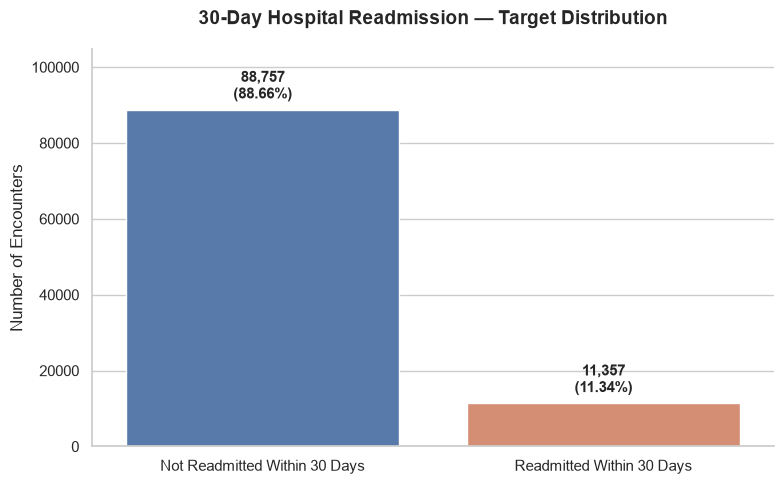

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

target_counts = (
    df_eligible["readmitted_30d"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = sns.barplot(
    x=["Not Readmitted Within 30 Days", "Readmitted Within 30 Days"],
    y=target_counts.values,
    palette=["#4978B8", "#E48763"],
    hue=["Not Readmitted Within 30 Days", "Readmitted Within 30 Days"],
    legend=False,
    ax=ax
)

for bar, count in zip(ax.patches, target_counts.values):
    ax.annotate(
        f"{count:,}\n({count / target_counts.sum() * 100:.2f}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        xytext=(0, 5),
        textcoords="offset points"
    )

ax.set_title("30-Day Hospital Readmission — Target Distribution",
             fontsize=14, fontweight="bold", pad=18)
ax.set_xlabel("")
ax.set_ylabel("Number of Encounters")
ax.set_ylim(0, target_counts.max() * 1.18)

sns.despine()
plt.tight_layout()
plt.show()


In [18]:

# Missingness analysis — eligible cohort
# No cleaning or modification of df_eligible

missing_report = []

for col in df_eligible.columns:
    s = df_eligible[col]

    actual_nulls = s.isna().sum()

    if pd.api.types.is_string_dtype(s):
        placeholders = (
            s.astype("string")
            .str.strip()
            .eq("?")
            .fillna(False)
            .sum()
        )
    else:
        placeholders = 0

    total_missing = actual_nulls + placeholders

    missing_report.append({
        "Feature": col,
        "Actual_NaN": actual_nulls,
        "Question_Mark": placeholders,
        "Total_Missing": total_missing,
        "Missing_Percent": round(
            total_missing / len(df_eligible) * 100, 2
        )
    })

missing_df = pd.DataFrame(missing_report)

missing_df = (
    missing_df[missing_df["Total_Missing"] > 0]
    .sort_values("Missing_Percent", ascending=False)
)

print("CONSOLIDATED MISSINGNESS REPORT")
print(missing_df.to_string(index=False))


CONSOLIDATED MISSINGNESS REPORT
          Feature  Actual_NaN  Question_Mark  Total_Missing  Missing_Percent
           weight           0          96958          96958            96.85
    max_glu_serum       94890              0          94890            94.78
        A1Cresult       83238              0          83238            83.14
medical_specialty           0          49129          49129            49.07
       payer_code           0          39591          39591            39.55
             race           0           2239           2239             2.24
           diag_3           0           1421           1421             1.42
           diag_2           0            358            358             0.36
           diag_1           0             21             21             0.02


In [19]:

# Examine readmission rates for missing vs observed features

features_to_check = [
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code",
    "race",
    "diag_1",
    "diag_2",
    "diag_3"
]

results = []

for col in features_to_check:
    s = df_eligible[col].astype("string")

    missing_mask = (
        s.isna() |
        s.str.strip().eq("?").fillna(False)
    )

    for status, mask in [
        ("Missing", missing_mask),
        ("Observed", ~missing_mask)
    ]:
        subset = df_eligible.loc[mask, "readmitted_30d"]

        results.append({
            "Feature": col,
            "Status": status,
            "Encounters": len(subset),
            "Readmission_Rate_%": round(
                subset.mean() * 100, 2
            ) if len(subset) else float("nan")
        })

missing_target_analysis = pd.DataFrame(results)

print("MISSINGNESS VS READMISSION ANALYSIS")
print(missing_target_analysis.to_string(index=False))


MISSINGNESS VS READMISSION ANALYSIS
          Feature   Status  Encounters  Readmission_Rate_%
           weight  Missing       96958               11.35
           weight Observed        3156               11.31
    max_glu_serum  Missing       94890               11.27
    max_glu_serum Observed        5224               12.65
        A1Cresult  Missing       83238               11.63
        A1Cresult Observed       16876                9.93
medical_specialty  Missing       49129               11.77
medical_specialty Observed       50985               10.94
       payer_code  Missing       39591               11.69
       payer_code Observed       60523               11.12
             race  Missing        2239                8.40
             race Observed       97875               11.41
           diag_1  Missing          21               23.81
           diag_1 Observed      100093               11.34
           diag_2  Missing         358                8.10
           diag_2 Ob

In [20]:

# Verify raw laboratory values without automatic NA conversion

raw_tests = pd.read_csv(
    DATA_DIR / "diabetic_data.csv",
    usecols=["max_glu_serum", "A1Cresult"],
    keep_default_na=False
)

for col in raw_tests.columns:
    print(f"\n{col.upper()} — ORIGINAL VALUES")
    print(raw_tests[col].value_counts(dropna=False).to_string())



MAX_GLU_SERUM — ORIGINAL VALUES
max_glu_serum
None    96420
Norm     2597
>200     1485
>300     1264

A1CRESULT — ORIGINAL VALUES
A1Cresult
None    84748
>8       8216
Norm     4990
>7       3812


In [21]:

# Analyze readmission by recorded weight category

weight_analysis = (
    df_eligible.loc[df_eligible["weight"] != "?"]
    .groupby("weight", observed=True)["readmitted_30d"]
    .agg(
        encounters="count",
        readmitted="sum",
        readmission_rate="mean"
    )
    .reset_index()
)

weight_analysis["readmission_rate"] = (
    weight_analysis["readmission_rate"] * 100
).round(2)

print("WEIGHT CATEGORY VS READMISSION")
print(weight_analysis.to_string(index=False))


WEIGHT CATEGORY VS READMISSION
   weight  encounters  readmitted  readmission_rate
     >200           3           0              0.00
   [0-25)          48           8             16.67
[100-125)         622          67             10.77
[125-150)         143          12              8.39
[150-175)          34           3              8.82
[175-200)          11           1              9.09
  [25-50)          94           8              8.51
  [50-75)         881         105             11.92
 [75-100)        1320         153             11.59


In [22]:

# Age-group analysis

age_analysis = (
    df_eligible.groupby("age", observed=True)["readmitted_30d"]
    .agg(
        encounters="count",
        readmitted="sum",
        readmission_rate="mean"
    )
    .reset_index()
    .sort_values("age")
)

age_analysis["readmission_rate"] = (
    age_analysis["readmission_rate"] * 100
).round(2)

print("AGE GROUP VS 30-DAY READMISSION")
print(age_analysis.to_string(index=False))


AGE GROUP VS 30-DAY READMISSION
     age  encounters  readmitted  readmission_rate
  [0-10)         160           3              1.88
 [10-20)         690          40              5.80
 [20-30)        1650         236             14.30
 [30-40)        3765         424             11.26
 [40-50)        9626        1027             10.67
 [50-60)       17102        1668              9.75
 [60-70)       22185        2502             11.28
 [70-80)       25562        3069             12.01
 [80-90)       16706        2078             12.44
[90-100)        2668         310             11.62


In [23]:

# Previous inpatient utilization vs readmission risk

inpatient_analysis = (
    df_eligible.groupby("number_inpatient")["readmitted_30d"]
    .agg(
        encounters="count",
        readmitted="sum",
        readmission_rate="mean"
    )
    .reset_index()
    .sort_values("number_inpatient")
)

inpatient_analysis["readmission_rate"] = (
    inpatient_analysis["readmission_rate"] * 100
).round(2)

print("PREVIOUS INPATIENT VISITS VS READMISSION")
print(inpatient_analysis.to_string(index=False))


PREVIOUS INPATIENT VISITS VS READMISSION
 number_inpatient  encounters  readmitted  readmission_rate
                0       66672        5706              8.56
                1       19163        2523             13.17
                2        7382        1319             17.87
                3        3321         692             20.84
                4        1588         383             24.12
                5         800         255             31.87
                6         477         166             34.80
                7         264          95             35.98
                8         146          67             45.89
                9         111          47             42.34
               10          59          26             44.07
               11          49          33             67.35
               12          34          17             50.00
               13          18          10             55.56
               14          10           4             40.00

In [24]:

# Analyze previous emergency and outpatient utilization

utilization_cols = [
    "number_emergency",
    "number_outpatient"
]

for col in utilization_cols:

    # Group visit counts to avoid unreliable tiny categories
    visit_groups = df_eligible[col].clip(upper=5)

    analysis = (
        df_eligible
        .groupby(visit_groups)["readmitted_30d"]
        .agg(
            encounters="count",
            readmitted="sum",
            readmission_rate="mean"
        )
        .reset_index()
    )

    analysis["readmission_rate"] = (
        analysis["readmission_rate"] * 100
    ).round(2)

    analysis[col] = analysis[col].astype(str)
    analysis.loc[analysis[col] == "5", col] = "5+"

    print(f"\n{'=' * 55}")
    print(f"{col.upper()} VS 30-DAY READMISSION")
    print(analysis.to_string(index=False))



NUMBER_EMERGENCY VS 30-DAY READMISSION
number_emergency  encounters  readmitted  readmission_rate
               0       88925        9467             10.65
               1        7538        1102             14.62
               2        2005         373             18.60
               3         713         147             20.62
               4         371         115             31.00
              5+         562         153             27.22

NUMBER_OUTPATIENT VS 30-DAY READMISSION
number_outpatient  encounters  readmitted  readmission_rate
                0       83624        9076             10.85
                1        8418        1190             14.14
                2        3542         494             13.95
                3        2017         251             12.44
                4        1083         166             15.33
               5+        1430         180             12.59


In [25]:

# Length of hospital stay vs 30-day readmission

stay_analysis = (
    df_eligible.groupby("time_in_hospital")["readmitted_30d"]
    .agg(
        encounters="count",
        readmitted="sum",
        readmission_rate="mean"
    )
    .reset_index()
    .sort_values("time_in_hospital")
)

stay_analysis["readmission_rate"] = (
    stay_analysis["readmission_rate"] * 100
).round(2)

print("HOSPITAL STAY DURATION VS 30-DAY READMISSION")
print(stay_analysis.to_string(index=False))


HOSPITAL STAY DURATION VS 30-DAY READMISSION
 time_in_hospital  encounters  readmitted  readmission_rate
                1       13878        1162              8.37
                2       16976        1712             10.08
                3       17546        1894             10.79
                4       13775        1644             11.93
                5        9834        1199             12.19
                6        7425         949             12.78
                7        5744         752             13.09
                8        4323         625             14.46
                9        2927         412             14.08
               10        2290         336             14.67
               11        1809         195             10.78
               12        1401         193             13.78
               13        1173         149             12.70
               14        1013         135             13.33


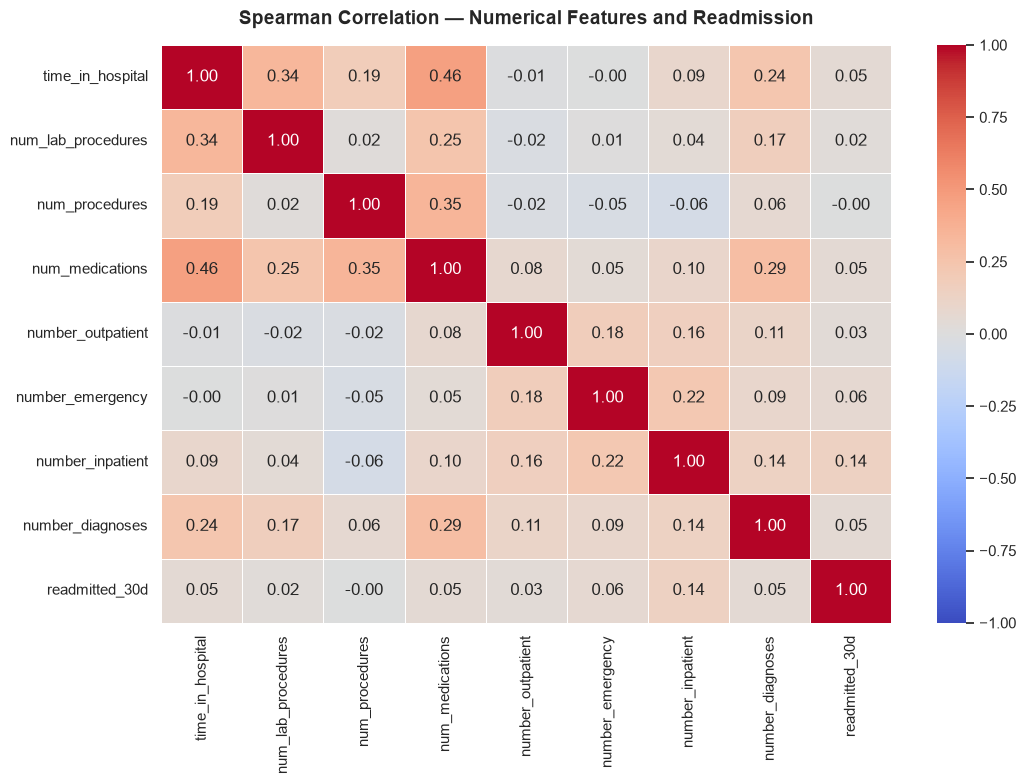

CORRELATION WITH READMISSION TARGET:
number_inpatient      0.140892
number_emergency      0.064129
time_in_hospital      0.051715
number_diagnoses      0.050145
num_medications       0.047462
number_outpatient     0.034247
num_lab_procedures    0.023468
num_procedures       -0.004339


In [26]:

# Numerical correlation analysis

numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

correlation_df = df_eligible[
    numerical_features + ["readmitted_30d"]
]

correlation_matrix = correlation_df.corr(method="spearman")

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Spearman Correlation — Numerical Features and Readmission",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.show()

print("CORRELATION WITH READMISSION TARGET:")
print(
    correlation_matrix["readmitted_30d"]
    .drop("readmitted_30d")
    .sort_values(ascending=False)
    .to_string()
)


In [27]:

# Numerical outlier audit using the IQR method

outlier_results = []

for col in numerical_features:
    s = df_eligible[col]

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (s < lower_bound) | (s > upper_bound)

    outlier_results.append({
        "Feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_mask.sum(),
        "Outlier_%": round(outlier_mask.mean() * 100, 2)
    })

outlier_report = pd.DataFrame(outlier_results)

print("NUMERICAL OUTLIER AUDIT")
print(outlier_report.to_string(index=False))


NUMERICAL OUTLIER AUDIT
           Feature   Q1   Q3  IQR  Lower_Bound  Upper_Bound  Outlier_Count  Outlier_%
  time_in_hospital  2.0  6.0  4.0         -4.0         12.0           2186       2.18
num_lab_procedures 31.0 57.0 26.0         -8.0         96.0            122       0.12
    num_procedures  0.0  2.0  2.0         -3.0          5.0           4811       4.81
   num_medications 10.0 20.0 10.0         -5.0         35.0           2470       2.47
 number_outpatient  0.0  0.0  0.0          0.0          0.0          16490      16.47
  number_emergency  0.0  0.0  0.0          0.0          0.0          11189      11.18
  number_inpatient  0.0  1.0  1.0         -1.5          2.5           6897       6.89
  number_diagnoses  6.0  9.0  3.0          1.5         13.5            278       0.28


In [28]:

# Admission type vs 30-day readmission

admission_mapping = mapping_tables["admission_type_id"]

admission_analysis = (
    df_eligible
    .groupby("admission_type_id")["readmitted_30d"]
    .agg(
        encounters="count",
        readmitted="sum",
        readmission_rate="mean"
    )
    .reset_index()
)

admission_analysis["admission_type"] = (
    admission_analysis["admission_type_id"]
    .map(admission_mapping)
)

admission_analysis["readmission_rate"] = (
    admission_analysis["readmission_rate"] * 100
).round(2)

admission_analysis = admission_analysis[
    [
        "admission_type_id",
        "admission_type",
        "encounters",
        "readmitted",
        "readmission_rate"
    ]
].sort_values("encounters", ascending=False)

print("ADMISSION TYPE VS 30-DAY READMISSION")
print(admission_analysis.to_string(index=False))


ADMISSION TYPE VS 30-DAY READMISSION
 admission_type_id admission_type  encounters  readmitted  readmission_rate
                 1      Emergency       52884        6221             11.76
                 3       Elective       18739        1961             10.46
                 2         Urgent       18226        2066             11.34
                 6           NULL        5227         586             11.21
                 5  Not Available        4690         495             10.55
                 8     Not Mapped         320          27              8.44
                 7  Trauma Center          18           0              0.00
                 4        Newborn          10           1             10.00


In [29]:

# Discharge disposition vs 30-day readmission

discharge_analysis = (
    df_eligible
    .groupby("discharge_disposition_id")["readmitted_30d"]
    .agg(
        encounters="count",
        readmitted="sum",
        readmission_rate="mean"
    )
    .reset_index()
)

discharge_analysis["description"] = (
    discharge_analysis["discharge_disposition_id"]
    .map(mapping_tables["discharge_disposition_id"])
)

discharge_analysis["readmission_rate"] = (
    discharge_analysis["readmission_rate"] * 100
).round(2)

discharge_analysis = discharge_analysis.sort_values(
    "encounters", ascending=False
)

print("DISCHARGE DISPOSITION VS READMISSION")
print(discharge_analysis.to_string(index=False))


DISCHARGE DISPOSITION VS READMISSION
 discharge_disposition_id  encounters  readmitted  readmission_rate                                                                                               description
                        1       60234        5602              9.30                                                                                        Discharged to home
                        3       13954        2046             14.66                                                                             Discharged/transferred to SNF
                        6       12902        1638             12.70                                                   Discharged/transferred to home with home health service
                       18        3691         459             12.44                                                                                                      NULL
                        2        2128         342             16.07                          

NameError: name 'FIGURE_DIR' is not defined

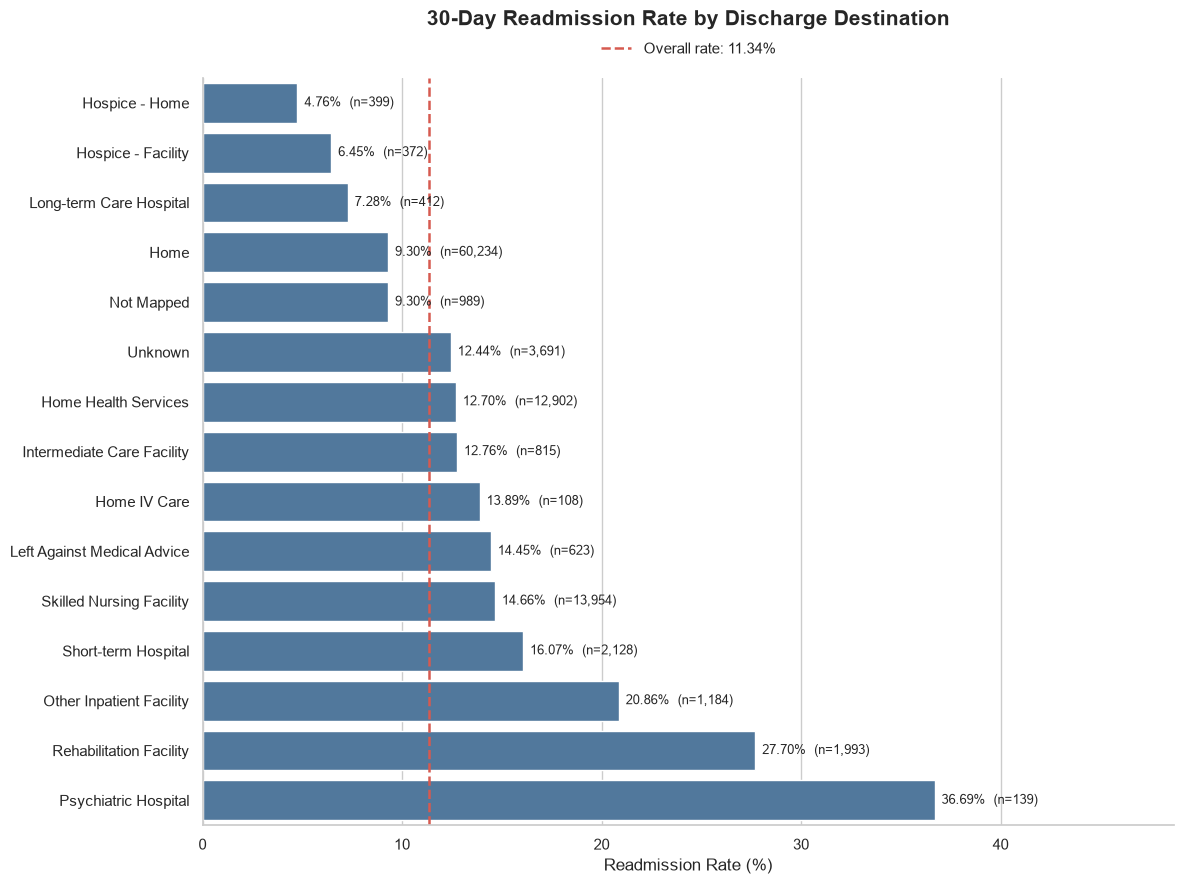

In [30]:

# Improved discharge destination visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Short, readable category names
discharge_labels = {
    1: "Home",
    2: "Short-term Hospital",
    3: "Skilled Nursing Facility",
    4: "Intermediate Care Facility",
    5: "Other Inpatient Facility",
    6: "Home Health Services",
    7: "Left Against Medical Advice",
    8: "Home IV Care",
    13: "Hospice - Home",
    14: "Hospice - Facility",
    18: "Unknown",
    22: "Rehabilitation Facility",
    23: "Long-term Care Hospital",
    25: "Not Mapped",
    28: "Psychiatric Hospital"
}

plot_df = discharge_analysis[
    discharge_analysis["encounters"] >= 100
].copy()

plot_df["category"] = (
    plot_df["discharge_disposition_id"]
    .map(discharge_labels)
    .fillna("Other")
)

plot_df = plot_df.sort_values("readmission_rate")

fig, ax = plt.subplots(figsize=(12, 9))

sns.barplot(
    data=plot_df,
    x="readmission_rate",
    y="category",
    color="#4479A8",
    ax=ax
)

for bar, (_, row) in zip(ax.patches, plot_df.iterrows()):
    ax.text(
        bar.get_width() + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{row['readmission_rate']:.2f}%  (n={row['encounters']:,})",
        va="center",
        fontsize=9
    )

overall_rate = df_eligible["readmitted_30d"].mean() * 100

ax.axvline(
    overall_rate,
    color="#D65A50",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall rate: {overall_rate:.2f}%"
)

ax.set_xlim(0, plot_df["readmission_rate"].max() + 12)

ax.set_title(
    "30-Day Readmission Rate by Discharge Destination",
    fontsize=15,
    fontweight="bold",
    pad=38
)

ax.set_xlabel("Readmission Rate (%)")
ax.set_ylabel("")

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.01),
    frameon=False
)

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "discharge_readmission_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


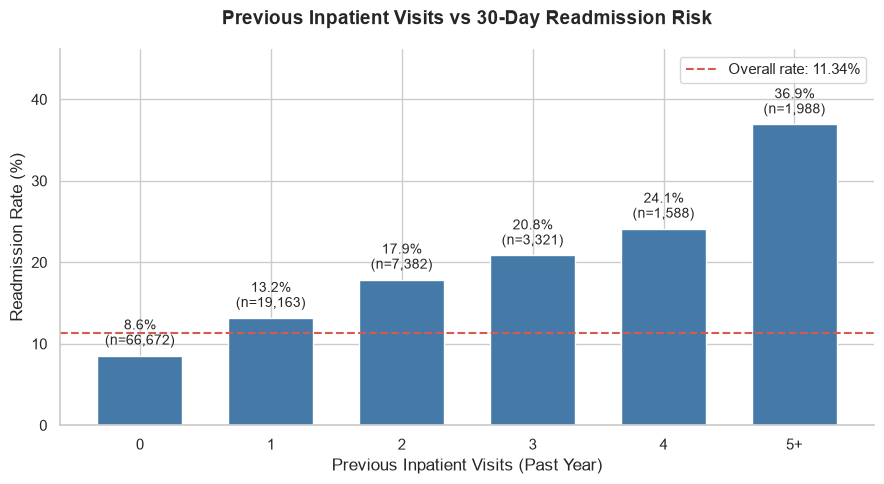

In [ ]:

# Previous inpatient visits vs readmission — visual EDA

plot_data = df_eligible[
    ["number_inpatient", "readmitted_30d"]
].copy()

# Group high visit counts for visualization only
plot_data["visit_group"] = (
    plot_data["number_inpatient"]
    .clip(upper=5)
)

summary = (
    plot_data.groupby("visit_group")["readmitted_30d"]
    .agg(
        encounters="count",
        readmissions="sum",
        rate="mean"
    )
    .reset_index()
)

summary["rate"] *= 100
summary["visit_group"] = summary["visit_group"].astype(str)
summary["visit_group"] = summary["visit_group"].replace({"5": "5+"})

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    summary["visit_group"],
    summary["rate"],
    color="#4479A8",
    width=0.65
)

for bar, (_, row) in zip(bars, summary.iterrows()):
    ax.annotate(
        f"{row['rate']:.1f}%\n(n={row['encounters']:,})",
        (bar.get_x() + bar.get_width()/2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=10,
        xytext=(0, 5),
        textcoords="offset points"
    )

overall_rate = df_eligible["readmitted_30d"].mean() * 100

ax.axhline(
    overall_rate,
    color="#D65A50",
    linestyle="--",
    label=f"Overall rate: {overall_rate:.2f}%"
)

ax.set_title(
    "Previous Inpatient Visits vs 30-Day Readmission Risk",
    fontsize=14,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Previous Inpatient Visits (Past Year)")
ax.set_ylabel("Readmission Rate (%)")
ax.set_ylim(0, summary["rate"].max() * 1.25)
ax.legend()

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "inpatient_visits_readmission.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


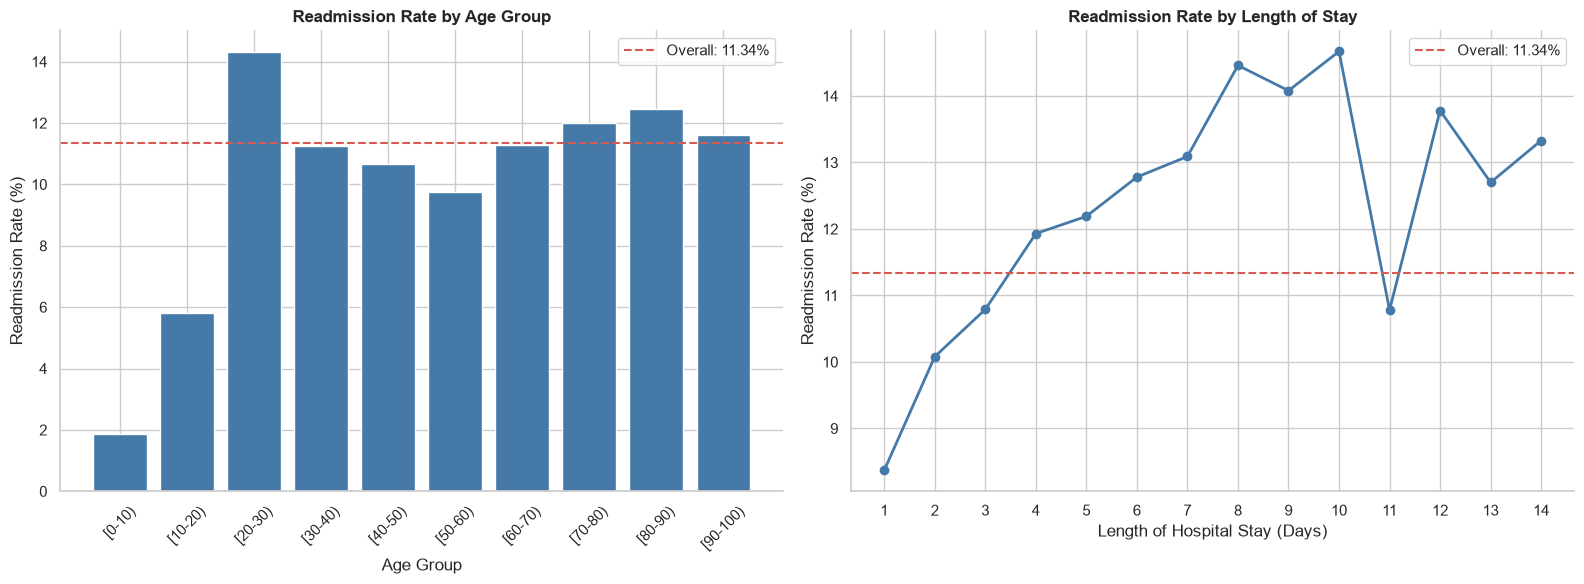

In [ ]:

# Age and hospital stay — visual EDA

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

overall_rate = df_eligible["readmitted_30d"].mean() * 100

# Plot 1: Age vs readmission rate
age_plot = age_analysis.copy()

axes[0].bar(
    age_plot["age"],
    age_plot["readmission_rate"],
    color="#4479A8"
)

axes[0].axhline(
    overall_rate,
    color="#D65A50",
    linestyle="--",
    label=f"Overall: {overall_rate:.2f}%"
)

axes[0].set_title("Readmission Rate by Age Group", fontweight="bold")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Readmission Rate (%)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

# Plot 2: Hospital stay vs readmission rate
axes[1].plot(
    stay_analysis["time_in_hospital"],
    stay_analysis["readmission_rate"],
    marker="o",
    linewidth=2,
    color="#4479A8"
)

axes[1].axhline(
    overall_rate,
    color="#D65A50",
    linestyle="--",
    label=f"Overall: {overall_rate:.2f}%"
)

axes[1].set_title("Readmission Rate by Length of Stay", fontweight="bold")
axes[1].set_xlabel("Length of Hospital Stay (Days)")
axes[1].set_ylabel("Readmission Rate (%)")
axes[1].set_xticks(range(1, 15))
axes[1].legend()

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "age_stay_readmission.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


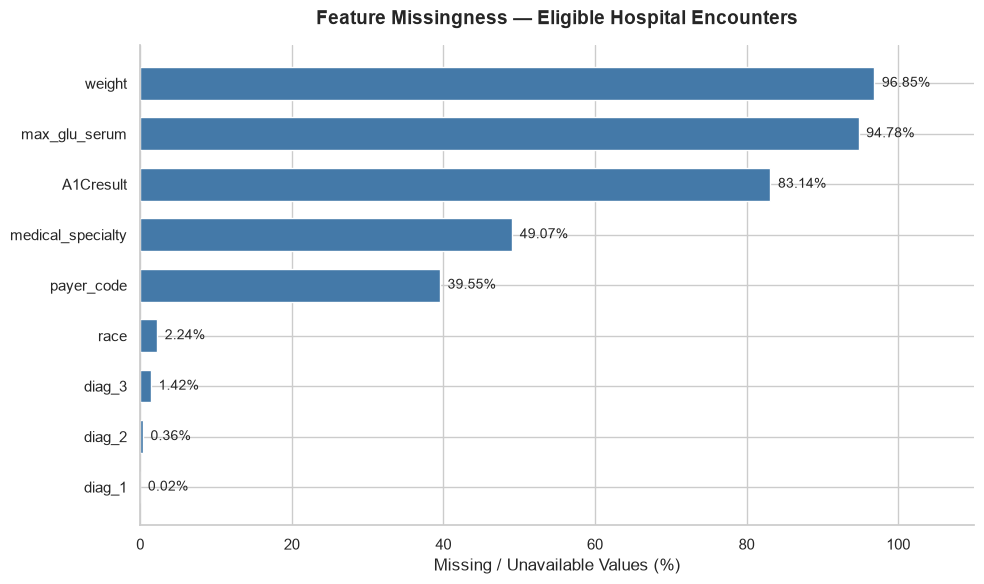

In [ ]:

# Visualize missingness across features

missing_plot = missing_df.sort_values(
    "Missing_Percent", ascending=True
).copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    missing_plot["Feature"],
    missing_plot["Missing_Percent"],
    color="#4479A8",
    height=0.65
)

for bar, percent in zip(
    bars, missing_plot["Missing_Percent"]
):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{percent:.2f}%",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Feature Missingness — Eligible Hospital Encounters",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Missing / Unavailable Values (%)")
ax.set_ylabel("")
ax.set_xlim(0, 110)

sns.despine()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "feature_missingness.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Analyze cardinality of categorical features

categorical_cols = df_eligible.select_dtypes(
    include=["object", "str", "string"]
).columns.tolist()

categorical_cols += [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

# Exclude original target
categorical_cols.remove("readmitted")

cardinality_report = pd.DataFrame({
    "Feature": categorical_cols,
    "Unique_Categories": [
        df_eligible[col].nunique(dropna=False)
        for col in categorical_cols
    ]
}).sort_values(
    "Unique_Categories", ascending=False
)

print("CATEGORICAL FEATURE CARDINALITY")
print(cardinality_report.to_string(index=False))


CATEGORICAL FEATURE CARDINALITY
                 Feature  Unique_Categories
                  diag_3                788
                  diag_2                748
                  diag_1                716
       medical_specialty                 73
discharge_disposition_id                 23
              payer_code                 18
     admission_source_id                 17
                  weight                 10
                     age                 10
       admission_type_id                  8
                    race                  6
     glyburide-metformin                  4
               metformin                  4
           max_glu_serum                  4
               A1Cresult                  4
             glimepiride                  4
               glipizide                  4
               glyburide                  4
            pioglitazone                  4
                acarbose                  4
             repaglinide                  4


In [ ]:

# Inspect diagnosis code formats and distributions

diagnosis_cols = ["diag_1", "diag_2", "diag_3"]

for col in diagnosis_cols:
    print(f"\n{'=' * 55}")
    print(f"FEATURE: {col}")

    print("\nTOP 15 MOST FREQUENT VALUES:")
    print(
        df_eligible[col]
        .value_counts(dropna=False)
        .head(15)
        .to_string()
    )

    print("\nSAMPLE UNIQUE VALUES:")
    print(
        df_eligible[col]
        .dropna()
        .unique()[:25]
    )

    print("\nVALUES STARTING WITH V OR E:")
    codes = df_eligible[col].astype("string")

    print(
        codes.str.startswith(("V", "E"), na=False).sum()
    )



FEATURE: diag_1

TOP 15 MOST FREQUENT VALUES:
diag_1
428      6735
414      6555
786      4016
410      3477
486      3413
427      2729
491      2252
715      2147
682      2030
780      2012
434      1958
996      1944
276      1861
250.8    1667
599      1581

SAMPLE UNIQUE VALUES:
<ArrowStringArray>
['250.83',    '276',    '648',      '8',    '197',    '414',    '428',
    '398',    '434',  '250.7',    '157',    '518',    '999',    '410',
    '682',    '402',    '737',    '572',    'V57',    '189',    '786',
    '427',    '996',    '277',    '584']
Length: 25, dtype: str

VALUES STARTING WITH V OR E:
1639

FEATURE: diag_2

TOP 15 MOST FREQUENT VALUES:
diag_2
276       6653
428       6531
250       6057
427       4928
401       3726
496       3269
599       3248
403       2761
414       2645
411       2554
250.02    2059
707       1975
585       1837
584       1583
250.01    1517

SAMPLE UNIQUE VALUES:
<ArrowStringArray>
[     '?', '250.01',    '250', '250.43',    '157',    '411', 

In [ ]:

import sys
from pathlib import Path

# Make src/ accessible from the notebook
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import group_icd9

# Apply grouping to a copy (preserve original columns)
diagnosis_df = df_eligible[
    ["diag_1", "diag_2", "diag_3"]
].copy()

for col in diagnosis_df.columns:
    diagnosis_df[f"{col}_group"] = (
        diagnosis_df[col].apply(group_icd9)
    )

# Inspect grouped categories
for col in ["diag_1", "diag_2", "diag_3"]:
    print(f"\n{'=' * 55}")
    print(f"{col.upper()} — GROUP DISTRIBUTION")
    print(
        diagnosis_df[f"{col}_group"]
        .value_counts()
        .to_string()
    )

print("\nSAMPLE ORIGINAL VS GROUPED DIAGNOSES:")
display(diagnosis_df.head(10))

print("\nVALIDATION:")
assert not diagnosis_df[
    ["diag_1_group", "diag_2_group", "diag_3_group"]
].isna().any().any()

print("All diagnosis values mapped successfully!")



DIAG_1 — GROUP DISTRIBUTION
diag_1_group
Circulatory            29782
Respiratory            10058
Digestive               9115
Diabetes                8693
Symptoms                7618
Injury_Poisoning        6881
Genitourinary           5015
Musculoskeletal         4944
Neoplasms               3299
Endocrine_Metabolic     2668
Infectious              2585
Skin                    2513
Mental                  2259
Supplementary_V         1638
Nervous_Sensory         1192
Blood                   1095
Pregnancy                687
Congenital                50
Missing                   21
External_Cause_E           1

DIAG_2 — GROUP DISTRIBUTION
diag_2_group
Circulatory            30892
Diabetes               12722
Respiratory             9864
Endocrine_Metabolic     8115
Genitourinary           7845
Symptoms                4544
Digestive               3907
Skin                    3567
Blood                   2889
Mental                  2648
Neoplasms               2452
Injury_Poisoning 

,diag_1,diag_2,diag_3,diag_1_group,diag_2_group,diag_3_group
0,250.83,?,?,Diabetes,Missing,Missing
1,276,250.01,255,Endocrine_Metabolic,Diabetes,Endocrine_Metabolic
2,648,250,V27,Pregnancy,Diabetes,Supplementary_V
3,8,250.43,403,Infectious,Diabetes,Circulatory
4,197,157,250,Neoplasms,Neoplasms,Diabetes
5,414,411,250,Circulatory,Circulatory,Diabetes
6,414,411,V45,Circulatory,Circulatory,Supplementary_V
7,428,492,250,Circulatory,Respiratory,Diabetes
8,398,427,38,Circulatory,Circulatory,Infectious
9,434,198,486,Circulatory,Neoplasms,Respiratory



VALIDATION:
All diagnosis values mapped successfully!


In [ ]:

# Final diagnosis mapping validation

group_cols = [
    "diag_1_group",
    "diag_2_group",
    "diag_3_group"
]

for col in group_cols:
    print(f"{col}:")
    print("  Categories:", diagnosis_df[col].nunique())
    print(
        "  Unknown mappings:",
        (diagnosis_df[col] == "Other_Unknown").sum()
    )
    print(
        "  Missing values:",
        (diagnosis_df[col] == "Missing").sum()
    )

assert all(
    (diagnosis_df[col] != "Other_Unknown").all()
    for col in group_cols
), "Unexpected diagnosis codes require inspection."

print("\nDiagnosis grouping validation passed!")


diag_1_group:
  Categories: 20
  Unknown mappings: 0
  Missing values: 21
diag_2_group:
  Categories: 20
  Unknown mappings: 0
  Missing values: 358
diag_3_group:
  Categories: 20
  Unknown mappings: 0
  Missing values: 1421

Diagnosis grouping validation passed!


In [ ]:

# Audit medication features before preprocessing

medication_cols = df_eligible.loc[
    :, "metformin":"metformin-pioglitazone"
].columns.tolist()

medication_audit = []

for col in medication_cols:
    counts = df_eligible[col].value_counts(dropna=False)

    medication_audit.append({
        "Feature": col,
        "Unique_Values": len(counts),
        "Most_Common": str(counts.index[0]),
        "Most_Common_%": round(counts.iloc[0] / len(df_eligible) * 100, 2),
        "Non_No_Count": df_eligible[col].ne("No").sum(),
        "Categories": ", ".join(map(str, counts.index))
    })

medication_report = pd.DataFrame(medication_audit)

print("MEDICATION FEATURE AUDIT")
print(medication_report.to_string(index=False))


MEDICATION FEATURE AUDIT
                 Feature  Unique_Values Most_Common  Most_Common_%  Non_No_Count           Categories
               metformin              4          No          80.12         19898 No, Steady, Up, Down
             repaglinide              4          No          98.47          1527 No, Steady, Up, Down
             nateglinide              4          No          99.31           695 No, Steady, Up, Down
          chlorpropamide              4          No          99.92            85 No, Steady, Up, Down
             glimepiride              4          No          94.86          5147 No, Steady, Up, Down
           acetohexamide              2          No         100.00             1           No, Steady
               glipizide              4          No          87.41         12605 No, Steady, Up, Down
               glyburide              4          No          89.45         10567 No, Steady, Up, Down
             tolbutamide              2          No      

In [31]:

from sklearn.model_selection import GroupShuffleSplit

SEED = 42

# First split: 70% train, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    train_size=0.70,
    random_state=SEED
)

train_idx, temp_idx = next(
    split1.split(
        df_eligible,
        y=df_eligible["readmitted_30d"],
        groups=df_eligible["patient_nbr"]
    )
)

train_df = df_eligible.iloc[train_idx].copy()
temp_df = df_eligible.iloc[temp_idx].copy()

# Second split: temporary data -> validation and test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=SEED
)

val_idx, test_idx = next(
    split2.split(
        temp_df,
        y=temp_df["readmitted_30d"],
        groups=temp_df["patient_nbr"]
    )
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Verify patient isolation
train_patients = set(train_df["patient_nbr"])
val_patients = set(val_df["patient_nbr"])
test_patients = set(test_df["patient_nbr"])

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("PATIENT-GROUPED SPLIT SUMMARY")

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(data):,} encounters | "
        f"{data['patient_nbr'].nunique():,} patients | "
        f"Positive rate: {data['readmitted_30d'].mean()*100:.2f}%"
    )

print("\nPatient overlap validation passed!")


PATIENT-GROUPED SPLIT SUMMARY
Train: 69,944 encounters | 49,307 patients | Positive rate: 11.30%
Validation: 15,172 encounters | 10,566 patients | Positive rate: 11.52%
Test: 14,998 encounters | 10,566 patients | Positive rate: 11.35%

Patient overlap validation passed!


In [32]:

# Verify split proportions and class distributions

split_summary = pd.DataFrame([
    {
        "Split": name,
        "Encounters": len(data),
        "Patients": data["patient_nbr"].nunique(),
        "Data_%": round(len(data) / len(df_eligible) * 100, 2),
        "Positive_%": round(data["readmitted_30d"].mean() * 100, 2)
    }
    for name, data in [
        ("Train", train_df),
        ("Validation", val_df),
        ("Test", test_df)
    ]
])

print(split_summary.to_string(index=False))

print("\nPATIENT OVERLAP:")
print("Train ∩ Validation:", len(set(train_df.patient_nbr) & set(val_df.patient_nbr)))
print("Train ∩ Test:", len(set(train_df.patient_nbr) & set(test_df.patient_nbr)))
print("Validation ∩ Test:", len(set(val_df.patient_nbr) & set(test_df.patient_nbr)))


     Split  Encounters  Patients  Data_%  Positive_%
     Train       69944     49307   69.86       11.30
Validation       15172     10566   15.15       11.52
      Test       14998     10566   14.98       11.35

PATIENT OVERLAP:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [33]:

# Step 31: Define baseline model features

target_col = "readmitted_30d"

exclude_cols = [
    "encounter_id",
    "patient_nbr",
    "readmitted",
    "readmitted_30d",
    "weight",
    "examide",
    "citoglipton"
]

# Fixed exclusions decided during EDA
rare_medications = [
    "acetohexamide",
    "tolbutamide",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

exclude_cols += rare_medications

feature_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
]

X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

y_train = train_df[target_col].copy()
y_val = val_df[target_col].copy()
y_test = test_df[target_col].copy()

print("Total input features before encoding:", len(feature_cols))

print("\nTRAIN:", X_train.shape, y_train.shape)
print("VALIDATION:", X_val.shape, y_val.shape)
print("TEST:", X_test.shape, y_test.shape)

print("\nSELECTED FEATURES:")
print(*feature_cols, sep="\n")

assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test.columns)

print("\nFeature schema validation passed!")


Total input features before encoding: 35

TRAIN: (69944, 35) (69944,)
VALIDATION: (15172, 35) (15172,)
TEST: (14998, 35) (14998,)

SELECTED FEATURES:
race
gender
age
admission_type_id
discharge_disposition_id
admission_source_id
time_in_hospital
payer_code
medical_specialty
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
diag_1
diag_2
diag_3
number_diagnoses
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
glipizide
glyburide
pioglitazone
rosiglitazone
acarbose
insulin
glyburide-metformin
change
diabetesMed

Feature schema validation passed!


In [37]:

import sys
from pathlib import Path

# Locate the project root
cwd = Path.cwd().resolve()

PROJECT_ROOT = (
    cwd if (cwd / "src").is_dir()
    else cwd.parent
)

# Add project root to Python's import search path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Current working directory:", cwd)
print("Project root:", PROJECT_ROOT)

# Import our reusable feature engineering function
from src.preprocessing import engineer_features

print("Feature engineering function imported successfully!")


# Apply identical feature engineering to all splits
X_train_fe = engineer_features(X_train)
X_val_fe = engineer_features(X_val)
X_test_fe = engineer_features(X_test)

print("FEATURE ENGINEERING SUMMARY")

for name, data in [
    ("Train", X_train_fe),
    ("Validation", X_val_fe),
    ("Test", X_test_fe)
]:
    print(f"{name}: {data.shape}")

# Verify consistent feature schema
assert X_train_fe.columns.equals(X_val_fe.columns)
assert X_train_fe.columns.equals(X_test_fe.columns)

# Validate engineered features
assert (
    X_train_fe["total_prior_visits"]
    == X_train_fe[
        ["number_inpatient", "number_emergency", "number_outpatient"]
    ].sum(axis=1)
).all()

assert not X_train_fe.isna().all(axis=1).any()

print("\nENGINEERED FEATURES:")
print([
    "total_prior_visits",
    "frequent_inpatient",
    "diabetes_diagnosis_flag",
    "diag_1_group",
    "diag_2_group",
    "diag_3_group"
])

print("\nSAMPLE ENGINEERED DATA:")
display(
    X_train_fe[
        [
            "number_inpatient",
            "number_emergency",
            "number_outpatient",
            "total_prior_visits",
            "frequent_inpatient",
            "diabetes_diagnosis_flag",
            "diag_1_group",
            "diag_2_group",
            "diag_3_group"
        ]
    ].head()
)

print("\nFeature engineering validation passed!")


Current working directory: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\notebooks
Project root: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction
Feature engineering function imported successfully!
FEATURE ENGINEERING SUMMARY
Train: (69944, 38)
Validation: (15172, 38)
Test: (14998, 38)

ENGINEERED FEATURES:
['total_prior_visits', 'frequent_inpatient', 'diabetes_diagnosis_flag', 'diag_1_group', 'diag_2_group', 'diag_3_group']

SAMPLE ENGINEERED DATA:


,number_inpatient,number_emergency,number_outpatient,total_prior_visits,frequent_inpatient,diabetes_diagnosis_flag,diag_1_group,diag_2_group,diag_3_group
0,0,0,0,0,0,1,Diabetes,Missing,Missing
1,0,0,0,0,0,1,Endocrine_Metabolic,Diabetes,Endocrine_Metabolic
3,0,0,0,0,0,1,Infectious,Diabetes,Circulatory
4,0,0,0,0,0,1,Neoplasms,Neoplasms,Diabetes
6,0,0,0,0,0,0,Circulatory,Circulatory,Supplementary_V



Feature engineering validation passed!


In [38]:

# Step 34: Identify preprocessing feature groups

categorical_id_cols = [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id"
]

binary_cols = [
    "frequent_inpatient",
    "diabetes_diagnosis_flag"
]

# Prevent categorical IDs from being treated as numerical
X_train_fe = X_train_fe.copy()
X_val_fe = X_val_fe.copy()
X_test_fe = X_test_fe.copy()

for data in [X_train_fe, X_val_fe, X_test_fe]:
    for col in categorical_id_cols:
        data[col] = data[col].astype(str)

numeric_cols = [
    col for col in X_train_fe.select_dtypes(include="number").columns
    if col not in binary_cols
]

categorical_cols = [
    col for col in X_train_fe.columns
    if col not in numeric_cols + binary_cols
]

print("NUMERICAL FEATURES:", len(numeric_cols))
print(*numeric_cols, sep="\n")

print("\nCATEGORICAL FEATURES:", len(categorical_cols))
print(*categorical_cols, sep="\n")

print("\nBINARY FEATURES:", len(binary_cols))
print(*binary_cols, sep="\n")

# Validate all columns are assigned exactly once
all_assigned = numeric_cols + categorical_cols + binary_cols

assert len(all_assigned) == len(set(all_assigned))
assert set(all_assigned) == set(X_train_fe.columns)

print("\nFeature grouping validation passed!")


NUMERICAL FEATURES: 9
time_in_hospital
num_lab_procedures
num_procedures
num_medications
number_outpatient
number_emergency
number_inpatient
number_diagnoses
total_prior_visits

CATEGORICAL FEATURES: 27
race
gender
age
admission_type_id
discharge_disposition_id
admission_source_id
payer_code
medical_specialty
max_glu_serum
A1Cresult
metformin
repaglinide
nateglinide
chlorpropamide
glimepiride
glipizide
glyburide
pioglitazone
rosiglitazone
acarbose
insulin
glyburide-metformin
change
diabetesMed
diag_1_group
diag_2_group
diag_3_group

BINARY FEATURES: 2
frequent_inpatient
diabetes_diagnosis_flag

Feature grouping validation passed!


In [40]:

import numpy as np

import importlib
import src.preprocessing as preprocessing

# Reload the updated preprocessing.py
importlib.reload(preprocessing)

# Import the newly added pipeline function
from src.preprocessing import build_preprocessing_pipeline

print("Reusable preprocessing pipeline imported successfully!")


# Create the complete reusable pipeline
preprocessor = build_preprocessing_pipeline()

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Reuse the fitted pipeline
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to TensorFlow-friendly float32
X_train_processed = X_train_processed.astype(np.float32)
X_val_processed = X_val_processed.astype(np.float32)
X_test_processed = X_test_processed.astype(np.float32)

print("PREPROCESSING RESULTS")
print("Train:", X_train_processed.shape)
print("Validation:", X_val_processed.shape)
print("Test:", X_test_processed.shape)

# Validate consistent input dimensions
assert (
    X_train_processed.shape[1]
    == X_val_processed.shape[1]
    == X_test_processed.shape[1]
)

# Check for missing and infinite values
for name, data in [
    ("Train", X_train_processed),
    ("Validation", X_val_processed),
    ("Test", X_test_processed),
]:
    assert np.isfinite(data).all(), f"{name} contains NaN/Inf!"

# Confirm target columns were excluded
feature_names = preprocessor.named_steps[
    "preprocessing"
].get_feature_names_out()

assert not any(
    "readmitted" in name.lower()
    for name in feature_names
)

print("\nTotal ANN input features:", len(feature_names))
print("Data type:", X_train_processed.dtype)
print("Missing/infinite values: None")
print("\nPipeline validation passed!")


Reusable preprocessing pipeline imported successfully!
PREPROCESSING RESULTS
Train: (69944, 281)
Validation: (15172, 281)
Test: (14998, 281)

Total ANN input features: 281
Data type: float32
Missing/infinite values: None

Pipeline validation passed!


In [41]:

import pandas as pd

feature_names = preprocessor.named_steps[
    "preprocessing"
].get_feature_names_out()

feature_audit = pd.DataFrame({
    "Feature_Name": feature_names
})

print("TOTAL FEATURES:", len(feature_audit))

print("\nFEATURES BY TRANSFORMATION:")
print(
    feature_audit["Feature_Name"]
    .str.split("__", n=1)
    .str[0]
    .value_counts()
)

print("\nLABORATORY FEATURES:")
display(
    feature_audit[
        feature_audit["Feature_Name"].str.contains(
            "A1Cresult|max_glu_serum",
            regex=True
        )
    ]
)

print("\nHOSPITAL ID FEATURES:")
display(
    feature_audit[
        feature_audit["Feature_Name"].str.contains(
            "admission_type_id|discharge_disposition_id|admission_source_id",
            regex=True
        )
    ].head(30)
)

print("\nTARGET LEAKAGE CHECK:")
assert not feature_audit["Feature_Name"].str.contains(
    "readmitted|patient_nbr|encounter_id",
    case=False
).any()

print("No direct target or patient identifier leakage detected!")


TOTAL FEATURES: 281

FEATURES BY TRANSFORMATION:
Feature_Name
categorical    270
numerical       11
Name: count, dtype: int64

LABORATORY FEATURES:


,Feature_Name
162,categorical__max_glu_serum_>200
163,categorical__max_glu_serum_>300
164,categorical__max_glu_serum_Norm
165,categorical__max_glu_serum_Not_Measured
166,categorical__A1Cresult_>7
167,categorical__A1Cresult_>8
168,categorical__A1Cresult_Norm
169,categorical__A1Cresult_Not_Measured



HOSPITAL ID FEATURES:


,Feature_Name
30,categorical__admission_type_id_1
31,categorical__admission_type_id_2
32,categorical__admission_type_id_3
33,categorical__admission_type_id_4
34,categorical__admission_type_id_7
35,categorical__admission_type_id_Unknown
36,categorical__discharge_disposition_id_1
37,categorical__discharge_disposition_id_10
38,categorical__discharge_disposition_id_12
39,categorical__discharge_disposition_id_13



TARGET LEAKAGE CHECK:
No direct target or patient identifier leakage detected!


In [42]:

import pandas as pd

# Inspect laboratory values after semantic cleaning
cleaned_train = preprocessor.named_steps[
    "semantic_cleaning"
].transform(
    preprocessor.named_steps[
        "feature_engineering"
    ].transform(X_train)
)

for col in ["A1Cresult", "max_glu_serum"]:
    print(f"\n{col} - Cleaned categories:")
    print(cleaned_train[col].value_counts(dropna=False))

    print(f"\n{col} - One-hot encoded columns:")
    print([
        name for name in feature_names
        if col in name
    ])

    assert cleaned_train[col].isna().sum() == 0
    assert "Not_Measured" in cleaned_train[col].unique()

print("\nLaboratory encoding validation passed!")



A1Cresult - Cleaned categories:
A1Cresult
Not_Measured    58106
>8               5692
Norm             3462
>7               2684
Name: count, dtype: int64

A1Cresult - One-hot encoded columns:
['categorical__A1Cresult_>7', 'categorical__A1Cresult_>8', 'categorical__A1Cresult_Norm', 'categorical__A1Cresult_Not_Measured']

max_glu_serum - Cleaned categories:
max_glu_serum
Not_Measured    66258
Norm             1840
>200             1006
>300              840
Name: count, dtype: int64

max_glu_serum - One-hot encoded columns:
['categorical__max_glu_serum_>200', 'categorical__max_glu_serum_>300', 'categorical__max_glu_serum_Norm', 'categorical__max_glu_serum_Not_Measured']

Laboratory encoding validation passed!


In [43]:

import pandas as pd

target_summary = []

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    target_summary.append({
        "Split": name,
        "Total": len(y),
        "Not_Readmitted_30d": (y == 0).sum(),
        "Readmitted_30d": (y == 1).sum(),
        "Positive_%": round(y.mean() * 100, 2)
    })

display(pd.DataFrame(target_summary))

assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

assert len(X_train_processed) == len(y_train)
assert len(X_val_processed) == len(y_val)
assert len(X_test_processed) == len(y_test)

print("Target and feature alignment validated!")


,Split,Total,Not_Readmitted_30d,Readmitted_30d,Positive_%
0,Train,69944,62037,7907,11.30
1,Validation,15172,13424,1748,11.52
2,Test,14998,13296,1702,11.35


Target and feature alignment validated!


In [44]:

import pandas as pd

target_summary = []

for name, y in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    target_summary.append({
        "Split": name,
        "Total": len(y),
        "Not_Readmitted_30d": (y == 0).sum(),
        "Readmitted_30d": (y == 1).sum(),
        "Positive_%": round(y.mean() * 100, 2)
    })

display(pd.DataFrame(target_summary))

assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

assert len(X_train_processed) == len(y_train)
assert len(X_val_processed) == len(y_val)
assert len(X_test_processed) == len(y_test)

print("Target and feature alignment validated!")


,Split,Total,Not_Readmitted_30d,Readmitted_30d,Positive_%
0,Train,69944,62037,7907,11.30
1,Validation,15172,13424,1748,11.52
2,Test,14998,13296,1702,11.35


Target and feature alignment validated!


In [46]:

import importlib
import numpy as np
import tensorflow as tf
import src.model as model_module

# Reload the updated model.py
importlib.reload(model_module)

# Set random seeds for reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Get the number of input features automatically
input_dim = X_train_processed.shape[1]

# Build our baseline ANN
baseline_model = model_module.build_baseline_mlp(
    input_dim=input_dim,
    learning_rate=0.001
)

print("TensorFlow Version:", tf.__version__)
print("Input Features:", input_dim)

# Inspect model architecture
baseline_model.summary()

print("\nTotal trainable parameters:",
      baseline_model.count_params())


TensorFlow Version: 2.22.0-rc0
Input Features: 281


Model: "hospital_readmission_baseline_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        18,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,161 (78.75 KB)

 Trainable params: 20,161 (78.75 KB)

 Non-trainable params: 0 (0.00 B)


Total trainable parameters: 20161


In [47]:

from pathlib import Path
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Save the best model inside our project
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

baseline_checkpoint_path = (
    MODEL_DIR / "baseline_readmission_mlp.keras"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

model_checkpoint = ModelCheckpoint(
    filepath=str(baseline_checkpoint_path),
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

baseline_callbacks = [
    early_stopping,
    model_checkpoint
]

BATCH_SIZE = 64
MAX_EPOCHS = 40

print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", 5)
print("Checkpoint path:", baseline_checkpoint_path)

print("\nBaseline training configuration ready!")


Batch size: 64
Maximum epochs: 40
Early stopping patience: 5
Checkpoint path: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\baseline_readmission_mlp.keras

Baseline training configuration ready!


In [48]:

import time

print("Starting baseline MLP training...")

start_time = time.time()

baseline_history = baseline_model.fit(
    X_train_processed,
    y_train.to_numpy().astype("float32"),

    validation_data=(
        X_val_processed,
        y_val.to_numpy().astype("float32")
    ),

    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=baseline_callbacks,
    shuffle=True,
    verbose=1
)

training_time = time.time() - start_time

print("\nBASELINE TRAINING COMPLETED")
print("Epochs trained:", len(baseline_history.history["loss"]))
print("Training time (seconds):", round(training_time, 2))

print(
    "Best validation loss:",
    round(min(baseline_history.history["val_loss"]), 4)
)

print(
    "Best validation PR-AUC:",
    round(max(baseline_history.history["val_pr_auc"]), 4)
)


Starting baseline MLP training...
Epoch 1/40
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8867 - loss: 0.3388 - pr_auc: 0.1924 - roc_auc: 0.6484
Epoch 1: val_loss improved from None to 0.33878, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\baseline_readmission_mlp.keras

Epoch 1: finished saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\baseline_readmission_mlp.keras
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.8867 - loss: 0.3388 - pr_auc: 0.1924 - roc_auc: 0.6484 - val_accuracy: 0.8850 - val_loss: 0.3388 - val_pr_auc: 0.2154 - val_roc_auc: 0.6647
Epoch 2/40
1090/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8870 - loss: 0.3324 - pr_auc: 0.2228 - roc_auc: 0.6740
Epoch 2: val_loss improved from 0.33878 to 0.33778, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\baseline_readmission_mlp.keras

Epoch 2: finished saving model to C:\Users\ASUS\Download

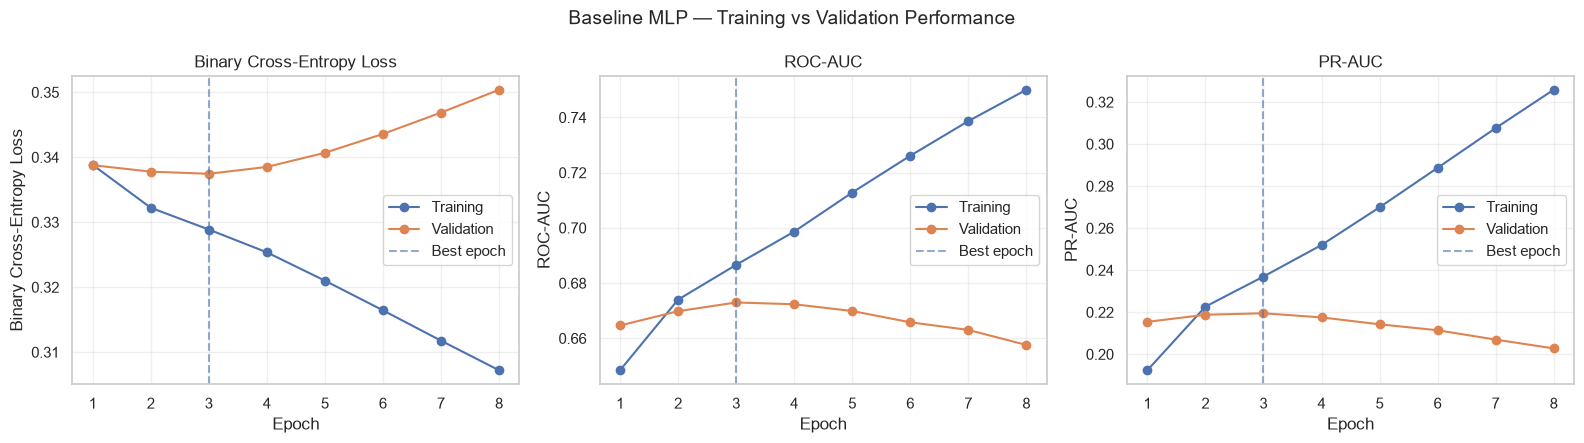

Training curves saved successfully!


In [49]:

import matplotlib.pyplot as plt
from pathlib import Path

history = baseline_history.history

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = [
    ("loss", "Binary Cross-Entropy Loss"),
    ("roc_auc", "ROC-AUC"),
    ("pr_auc", "PR-AUC")
]

epochs = range(1, len(history["loss"]) + 1)

for ax, (metric, title) in zip(axes, metrics):
    ax.plot(
        epochs,
        history[metric],
        marker="o",
        label="Training"
    )

    ax.plot(
        epochs,
        history[f"val_{metric}"],
        marker="o",
        label="Validation"
    )

    ax.axvline(
        3,
        linestyle="--",
        alpha=0.6,
        label="Best epoch"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Baseline MLP — Training vs Validation Performance",
    fontsize=14
)

plt.tight_layout()

figure_dir = PROJECT_ROOT / "reports" / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "baseline_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training curves saved successfully!")


In [50]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Predict probabilities on validation data only
val_probabilities = baseline_model.predict(
    X_val_processed,
    batch_size=256,
    verbose=0
).ravel()

# Convert probabilities into binary predictions
THRESHOLD = 0.50
val_predictions = (
    val_probabilities >= THRESHOLD
).astype(int)

y_val_true = y_val.to_numpy()

# Calculate evaluation metrics
metrics = {
    "Accuracy": accuracy_score(y_val_true, val_predictions),
    "Precision": precision_score(
        y_val_true, val_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val_true, val_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_val_true, val_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_val_true, val_probabilities
    ),
    "Average Precision": average_precision_score(
        y_val_true, val_probabilities
    )
}

print("BASELINE VALIDATION METRICS (threshold = 0.50)")
display(
    pd.DataFrame(
        metrics.items(),
        columns=["Metric", "Value"]
    ).round(4)
)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_val_true,
    val_predictions,
    labels=[0, 1]
).ravel()

print("\nCONFUSION MATRIX")
print(f"True Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

print("\nOPERATIONAL SUMMARY")
print("Actual readmissions:", int(y_val_true.sum()))
print("Readmissions identified:", tp)
print("Readmissions missed:", fn)
print("Encounters flagged:", int(val_predictions.sum()))
print(
    "Flagged encounter rate:",
    f"{val_predictions.mean() * 100:.2f}%"
)

assert len(val_probabilities) == len(y_val_true)
assert np.isfinite(val_probabilities).all()

print("\nValidation evaluation completed!")


BASELINE VALIDATION METRICS (threshold = 0.50)


,Metric,Value
0,Accuracy,0.8849
1,Precision,0.5161
2,Recall,0.0092
3,F1,0.0180
4,ROC-AUC,0.6728
5,Average Precision,0.2198



CONFUSION MATRIX
True Negatives : 13409
False Positives: 15
False Negatives: 1732
True Positives : 16

OPERATIONAL SUMMARY
Actual readmissions: 1748
Readmissions identified: 16
Readmissions missed: 1732
Encounters flagged: 31
Flagged encounter rate: 0.20%

Validation evaluation completed!


In [51]:

import pandas as pd
import numpy as np

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

threshold_results = []

for threshold in [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_true, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val_true, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Flagged_%": predictions.mean() * 100
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}",
        "Flagged_%": "{:.2f}%"
    })
)


,Threshold,Precision,Recall,F1,TP,FP,FN,Flagged_%
0,0.050000,0.132,0.928,0.231,1623,10699,125,81.22%
1,0.100000,0.167,0.692,0.269,1210,6027,538,47.70%
2,0.150000,0.205,0.440,0.280,769,2985,979,24.74%
3,0.200000,0.253,0.279,0.265,487,1435,1261,12.67%
4,0.250000,0.294,0.168,0.213,293,705,1455,6.58%
5,0.300000,0.315,0.094,0.145,164,356,1584,3.43%
6,0.400000,0.425,0.026,0.049,45,61,1703,0.70%
7,0.500000,0.516,0.009,0.018,16,15,1732,0.20%


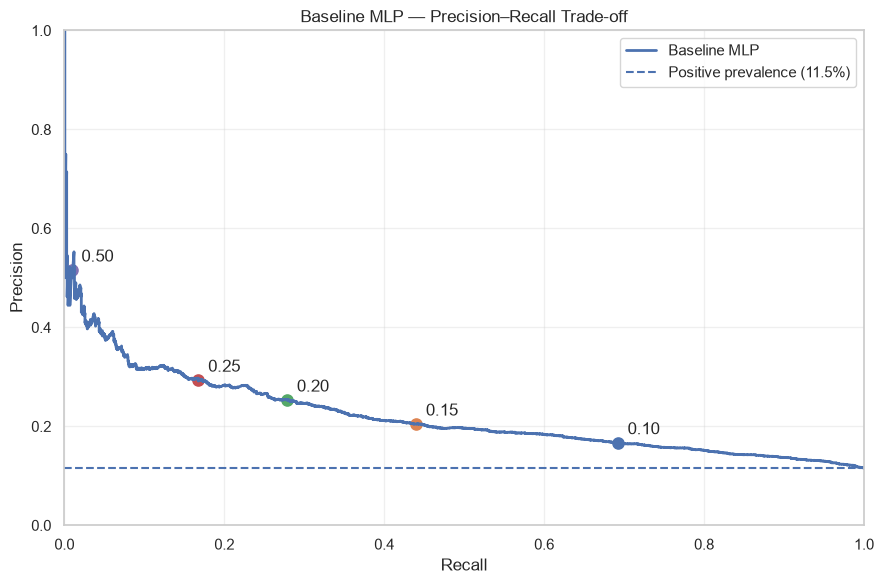

In [52]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_val_true,
    val_probabilities
)

plt.figure(figsize=(9, 6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label="Baseline MLP"
)

# Highlight selected threshold candidates
for threshold in [0.10, 0.15, 0.20, 0.25, 0.50]:
    predictions = (val_probabilities >= threshold).astype(int)

    tp = ((predictions == 1) & (y_val_true == 1)).sum()
    fp = ((predictions == 1) & (y_val_true == 0)).sum()
    fn = ((predictions == 0) & (y_val_true == 1)).sum()

    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0

    plt.scatter(r, p, s=65)
    plt.annotate(
        f"{threshold:.2f}",
        (r, p),
        xytext=(7, 6),
        textcoords="offset points"
    )

# Positive-class prevalence reference
prevalence = y_val_true.mean()

plt.axhline(
    prevalence,
    linestyle="--",
    label=f"Positive prevalence ({prevalence:.1%})"
)

plt.title("Baseline MLP — Precision–Recall Trade-off")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    figure_dir / "baseline_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [53]:

import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("TRAINING CLASS DISTRIBUTION:")
print(y_train.value_counts().sort_index())

print("\nCLASS WEIGHTS:")
print(class_weights)

print(
    "\nPositive-to-negative weight ratio:",
    round(class_weights[1] / class_weights[0], 2)
)


TRAINING CLASS DISTRIBUTION:
readmitted_30d
0    62037
1     7907
Name: count, dtype: int64

CLASS WEIGHTS:
{0: 0.563728097748118, 1: 4.42291640318705}

Positive-to-negative weight ratio: 7.85


In [54]:

import importlib
import tensorflow as tf
import src.model as model_module

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# Reload updated model.py without restarting Jupyter
importlib.reload(model_module)

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build regularized ANN
regularized_model = model_module.build_regularized_mlp(
    input_dim=X_train_processed.shape[1],
    learning_rate=0.001,
    l2_strength=0.001,
    dropout_rate=0.20
)

regularized_model.summary()

# Separate checkpoint from baseline
regularized_checkpoint_path = (
    MODEL_DIR / "regularized_weighted_readmission_mlp.keras"
)

regularized_callbacks = [
    EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(regularized_checkpoint_path),
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

print("\nRegularized training configuration ready!")
print("Class weights:", class_weights)
print("Checkpoint:", regularized_checkpoint_path)


Model: "hospital_readmission_regularized_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │        18,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,161 (78.75 KB)

 Trainable params: 20,161 (78.75 KB)

 Non-trainable params: 0 (0.00 B)


Regularized training configuration ready!
Class weights: {0: 0.563728097748118, 1: 4.42291640318705}
Checkpoint: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\regularized_weighted_readmission_mlp.keras


In [55]:

import time
import numpy as np

print("Training regularized, class-weighted MLP...")

start_time = time.time()

regularized_history = regularized_model.fit(
    X_train_processed,
    y_train.to_numpy().astype(np.float32),

    validation_data=(
        X_val_processed,
        y_val.to_numpy().astype(np.float32)
    ),

    epochs=40,
    batch_size=64,
    class_weight=class_weights,
    callbacks=regularized_callbacks,
    shuffle=True,
    verbose=1
)

training_time = time.time() - start_time

print("\nREGULARIZED MODEL TRAINING COMPLETED")
print("Epochs:", len(regularized_history.history["loss"]))
print("Training time:", round(training_time, 2), "seconds")

print(
    "Best validation PR-AUC:",
    round(max(regularized_history.history["val_pr_auc"]), 4)
)

print(
    "Best validation ROC-AUC:",
    round(max(regularized_history.history["val_roc_auc"]), 4)
)

print(
    "Best validation loss:",
    round(min(regularized_history.history["val_loss"]), 4)
)


Training regularized, class-weighted MLP...
Epoch 1/40
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6199 - loss: 0.7130 - pr_auc: 0.1889 - roc_auc: 0.6339
Epoch 1: val_pr_auc improved from None to 0.21684, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\regularized_weighted_readmission_mlp.keras

Epoch 1: finished saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\regularized_weighted_readmission_mlp.keras
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.6199 - loss: 0.7130 - pr_auc: 0.1889 - roc_auc: 0.6339 - val_accuracy: 0.6267 - val_loss: 0.6677 - val_pr_auc: 0.2168 - val_roc_auc: 0.6585 - learning_rate: 0.0010
Epoch 2/40
1092/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6253 - loss: 0.6723 - pr_auc: 0.2058 - roc_auc: 0.6595
Epoch 2: val_pr_auc improved from 0.21684 to 0.21986, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\regularized_weighted_readm

In [56]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    log_loss,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Probabilities from both models
baseline_probs = baseline_model.predict(
    X_val_processed, verbose=0
).ravel()

regularized_probs = regularized_model.predict(
    X_val_processed, verbose=0
).ravel()

comparison = []

for name, probs in [
    ("Baseline MLP", baseline_probs),
    ("Regularized + Weighted MLP", regularized_probs)
]:
    predictions = (probs >= 0.50).astype(int)

    comparison.append({
        "Model": name,
        "Log Loss (BCE)": log_loss(y_val_true, probs),
        "ROC-AUC": roc_auc_score(y_val_true, probs),
        "Average Precision": average_precision_score(
            y_val_true, probs
        ),
        "Precision @ 0.50": precision_score(
            y_val_true, predictions, zero_division=0
        ),
        "Recall @ 0.50": recall_score(
            y_val_true, predictions, zero_division=0
        ),
        "F1 @ 0.50": f1_score(
            y_val_true, predictions, zero_division=0
        ),
        "Flagged %": predictions.mean() * 100
    })

comparison_df = pd.DataFrame(comparison)

display(comparison_df.round(4))


,Model,Log Loss (BCE),ROC-AUC,Average Precision,Precision @ 0.50,Recall @ 0.50,F1 @ 0.50,Flagged %
0,Baseline MLP,0.3375,0.6728,0.2198,0.5161,0.0092,0.0180,0.2043
1,Regularized + Weighted MLP,0.6225,0.6748,0.2308,0.1837,0.5824,0.2792,36.5344


In [57]:

import pandas as pd

n_majority = int((y_train == 0).sum())
n_minority = int((y_train == 1).sum())

sampling_options = []

for majority_to_minority in [1, 2, 3, 4]:
    majority_retained = min(
        n_majority,
        majority_to_minority * n_minority
    )

    total = majority_retained + n_minority

    sampling_options.append({
        "Majority:Minority": f"{majority_to_minority}:1",
        "Negative retained": majority_retained,
        "Positive retained": n_minority,
        "Total training samples": total,
        "Positive %": round(n_minority / total * 100, 2),
        "Majority discarded": n_majority - majority_retained
    })

sampling_options_df = pd.DataFrame(sampling_options)

display(sampling_options_df)


,Majority:Minority,Negative retained,Positive retained,Total training samples,Positive %,Majority discarded
0,1:1,7907,7907,15814,50.00,54130
1,2:1,15814,7907,23721,33.33,46223
2,3:1,23721,7907,31628,25.00,38316
3,4:1,31628,7907,39535,20.00,30409


In [58]:

import numpy as np
from imblearn.under_sampling import RandomUnderSampler

# 3 negative encounters for every 1 positive encounter
sampler = RandomUnderSampler(
    sampling_strategy=1/3,
    random_state=42
)

X_train_under, y_train_under = sampler.fit_resample(
    X_train_processed,
    y_train.to_numpy()
)

print("BEFORE UNDERSAMPLING")
print("Features:", X_train_processed.shape)
print("Class counts:", np.bincount(y_train.to_numpy()))

print("\nAFTER UNDERSAMPLING")
print("Features:", X_train_under.shape)
print("Class counts:", np.bincount(y_train_under))
print("Positive rate:", round(y_train_under.mean() * 100, 2), "%")

# Sanity checks
assert X_train_under.shape[1] == X_train_processed.shape[1]
assert np.bincount(y_train_under).tolist() == [23721, 7907]
assert np.isfinite(X_train_under).all()

# TensorFlow-compatible data
X_train_under = X_train_under.astype(np.float32)
y_train_under = y_train_under.astype(np.float32)

print("\nTraining-only undersampling completed!")


BEFORE UNDERSAMPLING
Features: (69944, 281)
Class counts: [62037  7907]

AFTER UNDERSAMPLING
Features: (31628, 281)
Class counts: [23721  7907]
Positive rate: 25.0 %

Training-only undersampling completed!


In [59]:

import tensorflow as tf

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Same initialization seed for a fairer comparison
tf.keras.utils.set_random_seed(42)

# Fresh model — do not reuse trained weights
undersampled_model = model_module.build_regularized_mlp(
    input_dim=X_train_under.shape[1],
    learning_rate=0.001,
    l2_strength=0.001,
    dropout_rate=0.20
)

# Separate checkpoint
undersampled_checkpoint_path = (
    MODEL_DIR / "undersampled_readmission_mlp.keras"
)

undersampled_callbacks = [
    EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(undersampled_checkpoint_path),
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

print("Undersampled ANN initialized successfully!")
print("Training shape:", X_train_under.shape)
print("Validation shape:", X_val_processed.shape)
print("Trainable parameters:", undersampled_model.count_params())
print("Checkpoint:", undersampled_checkpoint_path)


Undersampled ANN initialized successfully!
Training shape: (31628, 281)
Validation shape: (15172, 281)
Trainable parameters: 20161
Checkpoint: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\undersampled_readmission_mlp.keras


In [60]:

import time
import numpy as np

print("Training 3:1 undersampled ANN...")

start_time = time.time()

undersampled_history = undersampled_model.fit(
    X_train_under,
    y_train_under,

    validation_data=(
        X_val_processed,
        y_val.to_numpy().astype(np.float32)
    ),

    epochs=40,
    batch_size=64,

    # No class weights: undersampling is our imbalance treatment
    callbacks=undersampled_callbacks,

    shuffle=True,
    verbose=1
)

training_time = time.time() - start_time

print("\nUNDERSAMPLED ANN TRAINING COMPLETED")
print("Epochs trained:", len(undersampled_history.history["loss"]))
print("Training time:", round(training_time, 2), "seconds")

best_epoch = (
    np.argmax(undersampled_history.history["val_pr_auc"]) + 1
)

print("Best epoch:", best_epoch)

print(
    "Best validation PR-AUC:",
    round(max(undersampled_history.history["val_pr_auc"]), 4)
)

print(
    "Best validation ROC-AUC:",
    round(max(undersampled_history.history["val_roc_auc"]), 4)
)

print(
    "Validation PR-AUC at best epoch:",
    round(
        undersampled_history.history["val_pr_auc"][best_epoch - 1],
        4
    )
)

print(
    "Validation ROC-AUC at best epoch:",
    round(
        undersampled_history.history["val_roc_auc"][best_epoch - 1],
        4
    )
)


Training 3:1 undersampled ANN...
Epoch 1/40
495/495 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7514 - loss: 0.6074 - pr_auc: 0.3549 - roc_auc: 0.6143
Epoch 1: val_pr_auc improved from None to 0.21307, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\undersampled_readmission_mlp.keras

Epoch 1: finished saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\undersampled_readmission_mlp.keras
495/495 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.7514 - loss: 0.6074 - pr_auc: 0.3549 - roc_auc: 0.6143 - val_accuracy: 0.8817 - val_loss: 0.4275 - val_pr_auc: 0.2131 - val_roc_auc: 0.6594 - learning_rate: 0.0010
Epoch 2/40
487/495 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7539 - loss: 0.5599 - pr_auc: 0.3901 - roc_auc: 0.6505
Epoch 2: val_pr_auc improved from 0.21307 to 0.21533, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\undersampled_readmission_mlp.keras

Epoch 2: finished savin

In [61]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    log_loss
)

models_to_compare = {
    "Baseline": baseline_model,
    "Class Weighted + Regularized": regularized_model,
    "3:1 Undersampled + Regularized": undersampled_model
}

comparison_results = []

for name, model in models_to_compare.items():

    probs = model.predict(
        X_val_processed,
        batch_size=256,
        verbose=0
    ).ravel()

    preds = (probs >= 0.50).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_true, preds, labels=[0, 1]
    ).ravel()

    comparison_results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val_true, probs),
        "Average Precision": average_precision_score(
            y_val_true, probs
        ),
        "BCE": log_loss(y_val_true, probs),
        "Precision": precision_score(
            y_val_true, preds, zero_division=0
        ),
        "Recall": recall_score(
            y_val_true, preds, zero_division=0
        ),
        "F1": f1_score(
            y_val_true, preds, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Flagged %": preds.mean() * 100
    })

comparison_3models = pd.DataFrame(comparison_results)

display(comparison_3models.round(4))


,Model,ROC-AUC,Average Precision,BCE,Precision,Recall,F1,TP,FP,FN,Flagged %
0,Baseline,0.6728,0.2198,0.3375,0.5161,0.0092,0.0180,16,15,1732,0.2043
1,Class Weighted + Regularized,0.6748,0.2308,0.6225,0.1837,0.5824,0.2792,1018,4525,730,36.5344
2,3:1 Undersampled + Regularized,0.6732,0.2320,0.3904,0.3361,0.1379,0.1955,241,476,1507,4.7258


In [62]:

import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score

rng = np.random.default_rng(42)

# Reproducible validation sample
sample_size = min(3000, len(y_val_true))
sample_idx = rng.choice(
    len(y_val_true),
    size=sample_size,
    replace=False
)

X_sample = X_val_processed[sample_idx].copy()
y_sample = y_val_true[sample_idx]

# Baseline average precision on the validation sample
original_probs = regularized_model.predict(
    X_sample,
    batch_size=256,
    verbose=0
).ravel()

original_ap = average_precision_score(
    y_sample,
    original_probs
)

# Get names of all encoded features
encoded_feature_names = preprocessor.named_steps[
    "preprocessing"
].get_feature_names_out()

importance_results = []

for i, feature_name in enumerate(encoded_feature_names):

    X_permuted = X_sample.copy()

    # Shuffle one processed feature
    X_permuted[:, i] = rng.permutation(X_permuted[:, i])

    permuted_probs = regularized_model.predict(
        X_permuted,
        batch_size=256,
        verbose=0
    ).ravel()

    permuted_ap = average_precision_score(
        y_sample,
        permuted_probs
    )

    importance_results.append({
        "Feature": feature_name,
        "AP_Drop": original_ap - permuted_ap
    })

importance_df = (
    pd.DataFrame(importance_results)
    .sort_values("AP_Drop", ascending=False)
)

print("Original sample Average Precision:", round(original_ap, 4))

print("\nTOP 20 IMPORTANT FEATURES:")
display(importance_df.head(20))

print("\nBOTTOM 20 FEATURES:")
display(importance_df.tail(20))


Original sample Average Precision: 0.2366

TOP 20 IMPORTANT FEATURES:


,Feature,AP_Drop
6,numerical__number_inpatient,0.066026
36,categorical__discharge_disposition_id_1,0.021785
45,categorical__discharge_disposition_id_22,0.013188
8,numerical__total_prior_visits,0.007596
44,categorical__discharge_disposition_id_2,0.004329
53,categorical__discharge_disposition_id_6,0.003728
50,categorical__discharge_disposition_id_3,0.003062
89,categorical__payer_code_Unknown,0.003059
266,categorical__diag_3_group_Endocrine_Metabolic,0.002520
119,categorical__medical_specialty_Orthopedics-Rec...,0.002275



BOTTOM 20 FEATURES:


,Feature,AP_Drop
239,categorical__diag_1_group_Supplementary_V,-0.000653
245,categorical__diag_2_group_Digestive,-0.000682
76,categorical__payer_code_CP,-0.000716
9,numerical__frequent_inpatient,-0.000731
225,categorical__diag_1_group_Digestive,-0.000825
199,categorical__pioglitazone_No,-0.000934
109,categorical__medical_specialty_InternalMedicine,-0.000960
222,categorical__diag_1_group_Circulatory,-0.000968
31,categorical__admission_type_id_2,-0.000990
192,categorical__glipizide_Steady,-0.001060


In [63]:

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

rng = np.random.default_rng(42)

# Reproducible validation subset
sample_idx = rng.choice(
    len(X_val),
    size=min(3000, len(X_val)),
    replace=False
)

X_sample_raw = X_val.iloc[sample_idx].copy()
y_sample = y_val.iloc[sample_idx].to_numpy()

# Original predictions through our fitted pipeline
X_sample_processed = preprocessor.transform(
    X_sample_raw
).astype(np.float32)

original_probs = regularized_model.predict(
    X_sample_processed,
    batch_size=256,
    verbose=0
).ravel()

original_ap = average_precision_score(
    y_sample, original_probs
)

# Groups of related raw features
feature_groups = {
    "Prior healthcare utilization": [
        "number_inpatient",
        "number_emergency",
        "number_outpatient"
    ],
    "Discharge destination": [
        "discharge_disposition_id"
    ],
    "Admission information": [
        "admission_type_id",
        "admission_source_id"
    ],
    "Diagnoses": [
        "diag_1", "diag_2", "diag_3"
    ],
    "Hospital stay and procedures": [
        "time_in_hospital",
        "num_lab_procedures",
        "num_procedures",
        "number_diagnoses"
    ],
    "Demographics": [
        "age", "gender", "race"
    ],
    "Laboratory results": [
        "A1Cresult", "max_glu_serum"
    ],
    "Administrative information": [
        "payer_code", "medical_specialty"
    ],
    "Medication information": [
        "metformin", "repaglinide", "nateglinide",
        "chlorpropamide", "glimepiride", "glipizide",
        "glyburide", "pioglitazone", "rosiglitazone",
        "acarbose", "insulin", "glyburide-metformin",
        "num_medications", "change", "diabetesMed"
    ]
}

group_importance = []

for group_name, columns in feature_groups.items():

    X_permuted = X_sample_raw.copy()

    # Same permutation for all columns within a group,
    # preserving relationships inside the group
    shuffled_idx = rng.permutation(len(X_permuted))

    X_permuted.loc[:, columns] = (
        X_sample_raw[columns]
        .iloc[shuffled_idx]
        .to_numpy()
    )

    # Reapply our fitted reusable pipeline
    X_permuted_processed = preprocessor.transform(
        X_permuted
    ).astype(np.float32)

    permuted_probs = regularized_model.predict(
        X_permuted_processed,
        batch_size=256,
        verbose=0
    ).ravel()

    permuted_ap = average_precision_score(
        y_sample, permuted_probs
    )

    group_importance.append({
        "Feature_Group": group_name,
        "Original_AP": original_ap,
        "Permuted_AP": permuted_ap,
        "AP_Drop": original_ap - permuted_ap
    })

group_importance_df = (
    pd.DataFrame(group_importance)
    .sort_values("AP_Drop", ascending=False)
)

print("Original AP:", round(original_ap, 4))
display(group_importance_df.round(4))


Original AP: 0.2366


,Feature_Group,Original_AP,Permuted_AP,AP_Drop
0,Prior healthcare utilization,0.2366,0.1516,0.0850
1,Discharge destination,0.2366,0.2033,0.0333
7,Administrative information,0.2366,0.2256,0.0110
3,Diagnoses,0.2366,0.2259,0.0107
4,Hospital stay and procedures,0.2366,0.2303,0.0063
2,Admission information,0.2366,0.2329,0.0037
6,Laboratory results,0.2366,0.2334,0.0032
8,Medication information,0.2366,0.2366,-0.0000
5,Demographics,0.2366,0.2370,-0.0004


In [64]:

# Step 61: Define reduced feature schema
# We retain num_medications as a general treatment-complexity count.

medication_columns_to_drop = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "glipizide",
    "glyburide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "insulin",
    "glyburide-metformin",
    "change",
    "diabetesMed"
]

assert set(medication_columns_to_drop).issubset(X_train.columns)

X_train_reduced = X_train.drop(
    columns=medication_columns_to_drop
).copy()

X_val_reduced = X_val.drop(
    columns=medication_columns_to_drop
).copy()

print("Original raw features:", X_train.shape[1])
print("Reduced raw features:", X_train_reduced.shape[1])

print("\nTRAIN:", X_train_reduced.shape)
print("VALIDATION:", X_val_reduced.shape)

assert X_train_reduced.columns.equals(X_val_reduced.columns)

print("\nMedication ablation feature sets prepared!")


Original raw features: 35
Reduced raw features: 21

TRAIN: (69944, 21)
VALIDATION: (15172, 21)

Medication ablation feature sets prepared!


In [65]:

from src.preprocessing import build_preprocessing_pipeline
import numpy as np

# Create a fresh, unfitted preprocessing pipeline
reduced_preprocessor = build_preprocessing_pipeline()

# Fit ONLY on reduced training features
X_train_reduced_processed = reduced_preprocessor.fit_transform(
    X_train_reduced
).astype(np.float32)

# Transform validation using the training-fitted pipeline
X_val_reduced_processed = reduced_preprocessor.transform(
    X_val_reduced
).astype(np.float32)

print("REDUCED PREPROCESSING RESULTS")
print("Train:", X_train_reduced_processed.shape)
print("Validation:", X_val_reduced_processed.shape)

# Validation checks
assert (
    X_train_reduced_processed.shape[1]
    == X_val_reduced_processed.shape[1]
)

assert np.isfinite(X_train_reduced_processed).all()
assert np.isfinite(X_val_reduced_processed).all()

reduced_feature_names = reduced_preprocessor.named_steps[
    "preprocessing"
].get_feature_names_out()

assert len(reduced_feature_names) == X_train_reduced_processed.shape[1]

print("\nOriginal ANN inputs:", X_train_processed.shape[1])
print("Reduced ANN inputs:", X_train_reduced_processed.shape[1])
print("\nReduced preprocessing validation passed!")


REDUCED PREPROCESSING RESULTS
Train: (69944, 230)
Validation: (15172, 230)

Original ANN inputs: 281
Reduced ANN inputs: 230

Reduced preprocessing validation passed!


In [66]:

import tensorflow as tf

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Reproducible initialization
tf.keras.utils.set_random_seed(42)

# Fresh model with 230 input features
reduced_model = model_module.build_regularized_mlp(
    input_dim=X_train_reduced_processed.shape[1],
    learning_rate=0.001,
    l2_strength=0.001,
    dropout_rate=0.20
)

# Separate checkpoint
reduced_checkpoint_path = (
    MODEL_DIR / "reduced_features_weighted_mlp.keras"
)

reduced_callbacks = [
    EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(reduced_checkpoint_path),
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

# Train using the original class distribution and class weights
reduced_history = reduced_model.fit(
    X_train_reduced_processed,
    y_train.to_numpy().astype("float32"),

    validation_data=(
        X_val_reduced_processed,
        y_val.to_numpy().astype("float32")
    ),

    epochs=40,
    batch_size=64,
    class_weight=class_weights,
    callbacks=reduced_callbacks,
    shuffle=True,
    verbose=1
)

best_epoch = (
    int(tf.argmax(reduced_history.history["val_pr_auc"])) + 1
)

print("\nREDUCED-FEATURE ANN TRAINING COMPLETE")
print("Best epoch:", best_epoch)
print("Total epochs:", len(reduced_history.history["loss"]))
print(
    "Best validation PR-AUC:",
    round(max(reduced_history.history["val_pr_auc"]), 4)
)
print(
    "Validation ROC-AUC at best epoch:",
    round(reduced_history.history["val_roc_auc"][best_epoch - 1], 4)
)


Epoch 1/40
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6250 - loss: 0.7120 - pr_auc: 0.1914 - roc_auc: 0.6374
Epoch 1: val_pr_auc improved from None to 0.21778, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\reduced_features_weighted_mlp.keras

Epoch 1: finished saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\reduced_features_weighted_mlp.keras
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.6250 - loss: 0.7120 - pr_auc: 0.1914 - roc_auc: 0.6374 - val_accuracy: 0.6310 - val_loss: 0.6631 - val_pr_auc: 0.2178 - val_roc_auc: 0.6609 - learning_rate: 0.0010
Epoch 2/40
1091/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6278 - loss: 0.6716 - pr_auc: 0.2079 - roc_auc: 0.6613
Epoch 2: val_pr_auc improved from 0.21778 to 0.22048, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\reduced_features_weighted_mlp.keras

Epoch 2: finished saving model to C:\Users\ASUS

In [67]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Predict using the reduced-feature model
reduced_probs = reduced_model.predict(
    X_val_reduced_processed,
    batch_size=256,
    verbose=0
).ravel()

# Use the same threshold for comparison
reduced_preds = (reduced_probs >= 0.50).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val_true,
    reduced_preds,
    labels=[0, 1]
).ravel()

reduced_metrics = {
    "Model": "Reduced Features + Weighted",
    "ROC-AUC": roc_auc_score(y_val_true, reduced_probs),
    "Average Precision": average_precision_score(
        y_val_true, reduced_probs
    ),
    "BCE": log_loss(y_val_true, reduced_probs),
    "Precision": precision_score(
        y_val_true, reduced_preds, zero_division=0
    ),
    "Recall": recall_score(
        y_val_true, reduced_preds, zero_division=0
    ),
    "F1": f1_score(
        y_val_true, reduced_preds, zero_division=0
    ),
    "TP": tp,
    "FP": fp,
    "FN": fn,
    "Flagged %": reduced_preds.mean() * 100
}

# Add the new model to the existing comparison
comparison_4models = pd.concat(
    [
        comparison_3models,
        pd.DataFrame([reduced_metrics])
    ],
    ignore_index=True
)

print("FOUR-MODEL VALIDATION COMPARISON")
display(comparison_4models.round(4))


FOUR-MODEL VALIDATION COMPARISON


,Model,ROC-AUC,Average Precision,BCE,Precision,Recall,F1,TP,FP,FN,Flagged %
0,Baseline,0.6728,0.2198,0.3375,0.5161,0.0092,0.0180,16,15,1732,0.2043
1,Class Weighted + Regularized,0.6748,0.2308,0.6225,0.1837,0.5824,0.2792,1018,4525,730,36.5344
2,3:1 Undersampled + Regularized,0.6732,0.2320,0.3904,0.3361,0.1379,0.1955,241,476,1507,4.7258
3,Reduced Features + Weighted,0.6776,0.2334,0.6387,0.1809,0.6196,0.2800,1083,4905,665,39.4674


In [68]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score
)

# Train a transparent tabular benchmark
logistic_model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    solver="lbfgs",
    random_state=42
)

logistic_model.fit(
    X_train_processed,
    y_train
)

# Evaluate on validation only
lr_probs = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

lr_preds = (lr_probs >= 0.50).astype(int)

lr_results = {
    "Model": "Logistic Regression (Balanced)",
    "ROC-AUC": roc_auc_score(y_val_true, lr_probs),
    "Average Precision": average_precision_score(
        y_val_true, lr_probs
    ),
    "Precision": precision_score(
        y_val_true, lr_preds, zero_division=0
    ),
    "Recall": recall_score(
        y_val_true, lr_preds, zero_division=0
    ),
    "F1": f1_score(
        y_val_true, lr_preds, zero_division=0
    ),
    "Flagged %": lr_preds.mean() * 100
}

display(
    pd.DataFrame([lr_results]).round(4)
)

print("Logistic Regression benchmark completed!")


,Model,ROC-AUC,Average Precision,Precision,Recall,F1,Flagged %
0,Logistic Regression (Balanced),0.6661,0.2224,0.1831,0.5549,0.2753,34.9196


Logistic Regression benchmark completed!


In [69]:

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

# All predictions are on the same validation set
model_scores = {
    "Baseline MLP": baseline_model.predict(
        X_val_processed, verbose=0
    ).ravel(),

    "Weighted MLP": regularized_model.predict(
        X_val_processed, verbose=0
    ).ravel(),

    "Undersampled MLP": undersampled_model.predict(
        X_val_processed, verbose=0
    ).ravel(),

    "Reduced-feature MLP": reduced_model.predict(
        X_val_reduced_processed, verbose=0
    ).ravel(),

    "Logistic Regression": logistic_model.predict_proba(
        X_val_processed
    )[:, 1]
}

alert_budgets = [0.10, 0.20, 0.30]

budget_results = []
n = len(y_val_true)
total_positives = int(y_val_true.sum())

for model_name, scores in model_scores.items():
    for budget in alert_budgets:

        # Select exactly the highest-scoring encounters
        k = int(np.ceil(budget * n))
        top_indices = np.argsort(-scores, kind="stable")[:k]

        tp = int(y_val_true[top_indices].sum())
        fp = k - tp
        fn = total_positives - tp

        budget_results.append({
            "Model": model_name,
            "Alert Budget": f"{budget:.0%}",
            "Flagged": k,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": tp / k,
            "Recall": tp / total_positives
        })

budget_df = pd.DataFrame(budget_results)

display(
    budget_df.sort_values(
        ["Alert Budget", "Recall"],
        ascending=[True, False]
    ).round(4)
)


,Model,Alert Budget,Flagged,TP,FP,FN,Precision,Recall
6,Undersampled MLP,10%,1518,421,1097,1327,0.2773,0.2408
0,Baseline MLP,10%,1518,414,1104,1334,0.2727,0.2368
3,Weighted MLP,10%,1518,411,1107,1337,0.2708,0.2351
9,Reduced-feature MLP,10%,1518,404,1114,1344,0.2661,0.2311
12,Logistic Regression,10%,1518,395,1123,1353,0.2602,0.2260
10,Reduced-feature MLP,20%,3035,687,2348,1061,0.2264,0.3930
4,Weighted MLP,20%,3035,675,2360,1073,0.2224,0.3862
7,Undersampled MLP,20%,3035,668,2367,1080,0.2201,0.3822
1,Baseline MLP,20%,3035,661,2374,1087,0.2178,0.3781
13,Logistic Regression,20%,3035,653,2382,1095,0.2152,0.3736


In [70]:

import importlib
import tensorflow as tf
import numpy as np
import src.model as model_module

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

# Reload newly updated model.py
importlib.reload(model_module)

tf.keras.utils.set_random_seed(42)

# Create a fresh compact model
compact_model = model_module.build_compact_mlp(
    input_dim=X_train_reduced_processed.shape[1],
    learning_rate=0.001,
    l2_strength=0.001,
    dropout_rate=0.20
)

compact_model.summary()

compact_checkpoint_path = (
    MODEL_DIR / "compact_weighted_readmission_mlp.keras"
)

compact_callbacks = [
    EarlyStopping(
        monitor="val_pr_auc",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_pr_auc",
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(compact_checkpoint_path),
        monitor="val_pr_auc",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

# Train on reduced features, with class weighting
compact_history = compact_model.fit(
    X_train_reduced_processed,
    y_train.to_numpy().astype(np.float32),
    validation_data=(
        X_val_reduced_processed,
        y_val.to_numpy().astype(np.float32)
    ),
    epochs=40,
    batch_size=64,
    class_weight=class_weights,
    callbacks=compact_callbacks,
    shuffle=True,
    verbose=1
)

best_epoch = (
    int(np.argmax(compact_history.history["val_pr_auc"])) + 1
)

print("\nCOMPACT ANN TRAINING COMPLETE")
print("Trainable parameters:", compact_model.count_params())
print("Epochs trained:", len(compact_history.history["loss"]))
print("Best epoch:", best_epoch)
print(
    "Best validation PR-AUC:",
    round(compact_history.history["val_pr_auc"][best_epoch - 1], 4)
)
print(
    "Validation ROC-AUC at best epoch:",
    round(compact_history.history["val_roc_auc"][best_epoch - 1], 4)
)


Model: "hospital_readmission_compact_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 32)             │         7,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,937 (31.00 KB)

 Trainable params: 7,937 (31.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6080 - loss: 0.6990 - pr_auc: 0.1862 - roc_auc: 0.6298
Epoch 1: val_pr_auc improved from None to 0.21865, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\compact_weighted_readmission_mlp.keras

Epoch 1: finished saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\compact_weighted_readmission_mlp.keras
1093/1093 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.6080 - loss: 0.6990 - pr_auc: 0.1862 - roc_auc: 0.6298 - val_accuracy: 0.6078 - val_loss: 0.6786 - val_pr_auc: 0.2186 - val_roc_auc: 0.6609 - learning_rate: 0.0010
Epoch 2/40
1086/1093 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6083 - loss: 0.6713 - pr_auc: 0.2041 - roc_auc: 0.6586
Epoch 2: val_pr_auc improved from 0.21865 to 0.22192, saving model to C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\compact_weighted_readmission_mlp.keras

Epoch 2: finished saving model to C:\U

In [71]:

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

models = {
    "Reduced 64-32 MLP": reduced_model,
    "Compact 32-16 MLP": compact_model
}

results = []
n = len(y_val_true)
total_positives = int(y_val_true.sum())

for model_name, model in models.items():

    probs = model.predict(
        X_val_reduced_processed,
        batch_size=256,
        verbose=0
    ).ravel()

    roc = roc_auc_score(y_val_true, probs)
    ap = average_precision_score(y_val_true, probs)

    for budget in [0.10, 0.20, 0.30]:

        k = int(np.ceil(n * budget))

        top_idx = np.argsort(
            -probs,
            kind="stable"
        )[:k]

        tp = int(y_val_true[top_idx].sum())
        fp = k - tp
        fn = total_positives - tp

        results.append({
            "Model": model_name,
            "ROC-AUC": roc,
            "Average Precision": ap,
            "Alert Budget": f"{budget:.0%}",
            "Flagged": k,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": tp / k,
            "Recall": tp / total_positives
        })

compact_comparison_df = pd.DataFrame(results)

display(
    compact_comparison_df.sort_values(
        ["Alert Budget", "Recall"],
        ascending=[True, False]
    ).round(4)
)


,Model,ROC-AUC,Average Precision,Alert Budget,Flagged,TP,FP,FN,Precision,Recall
3,Compact 32-16 MLP,0.6749,0.2313,10%,1518,407,1111,1341,0.2681,0.2328
0,Reduced 64-32 MLP,0.6776,0.2334,10%,1518,404,1114,1344,0.2661,0.2311
1,Reduced 64-32 MLP,0.6776,0.2334,20%,3035,687,2348,1061,0.2264,0.3930
4,Compact 32-16 MLP,0.6749,0.2313,20%,3035,673,2362,1075,0.2217,0.3850
2,Reduced 64-32 MLP,0.6776,0.2334,30%,4552,897,3655,851,0.1971,0.5132
5,Compact 32-16 MLP,0.6749,0.2313,30%,4552,895,3657,853,0.1966,0.5120


In [72]:

import joblib
from pathlib import Path

# Save the fitted reduced-feature preprocessing pipeline
pipeline_path = (
    MODEL_DIR / "reduced_features_preprocessor.joblib"
)

joblib.dump(
    reduced_preprocessor,
    pipeline_path
)

print("Selected ANN: Reduced-feature 64→32 MLP")
print("Model checkpoint:", reduced_checkpoint_path)
print("Preprocessing pipeline:", pipeline_path)

print("\nSaved artifacts:")
print("Model exists:", reduced_checkpoint_path.exists())
print("Pipeline exists:", pipeline_path.exists())


Selected ANN: Reduced-feature 64→32 MLP
Model checkpoint: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\reduced_features_weighted_mlp.keras
Preprocessing pipeline: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\reduced_features_preprocessor.joblib

Saved artifacts:
Model exists: True
Pipeline exists: True


In [73]:

import json
import numpy as np

# Final model configuration
FINAL_ALERT_BUDGET = 0.20

# Predict on validation only
final_val_probs = reduced_model.predict(
    X_val_reduced_processed,
    batch_size=256,
    verbose=0
).ravel()

# Find the score cutoff for the highest-risk 20%
k = int(np.ceil(len(final_val_probs) * FINAL_ALERT_BUDGET))

sorted_scores = np.sort(final_val_probs)[::-1]

# Midpoint between the final selected and first excluded score
final_threshold = float(
    (sorted_scores[k - 1] + sorted_scores[k]) / 2
)

# Confirm the selected operating point
final_val_preds = (final_val_probs >= final_threshold).astype(int)

assert final_val_preds.sum() == k, (
    "Boundary scores are tied; exact 20% cutoff needs tie handling."
)

# Save model configuration and raw input schema
model_config = {
    "model_name": "reduced_features_weighted_mlp",
    "model_file": reduced_checkpoint_path.name,
    "preprocessor_file": pipeline_path.name,
    "raw_feature_columns": X_train_reduced.columns.tolist(),
    "input_dim": int(X_train_reduced_processed.shape[1]),
    "decision_threshold": final_threshold,
    "validation_alert_budget": FINAL_ALERT_BUDGET,
    "threshold_selection": "top_20_percent_validation_scores",
    "random_seed": 42
}

config_path = MODEL_DIR / "final_model_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(model_config, f, indent=4)

print("FINAL MODEL CONFIGURATION")
print("Model:", model_config["model_name"])
print("Raw features:", len(model_config["raw_feature_columns"]))
print("ANN input dimension:", model_config["input_dim"])
print("Frozen score threshold:", round(final_threshold, 6))
print("Validation encounters flagged:", int(final_val_preds.sum()))
print("Validation flagged percentage:",
      round(final_val_preds.mean() * 100, 2), "%")

print("\nConfiguration saved:", config_path)


FINAL MODEL CONFIGURATION
Model: reduced_features_weighted_mlp
Raw features: 21
ANN input dimension: 230
Frozen score threshold: 0.612904
Validation encounters flagged: 3035
Validation flagged percentage: 20.0 %

Configuration saved: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\models\final_model_config.json


In [74]:

import json
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    confusion_matrix
)

# 1. Load the frozen configuration
with open(config_path, "r", encoding="utf-8") as f:
    final_config = json.load(f)

# 2. Load saved preprocessing and model
final_preprocessor = joblib.load(
    MODEL_DIR / final_config["preprocessor_file"]
)

final_model = tf.keras.models.load_model(
    MODEL_DIR / final_config["model_file"]
)

# 3. Apply the frozen raw-feature schema
final_feature_cols = final_config["raw_feature_columns"]

X_test_final = X_test.loc[:, final_feature_cols].copy()

# Transform using training-fitted preprocessing
X_test_final_processed = final_preprocessor.transform(
    X_test_final
).astype(np.float32)

assert (
    X_test_final_processed.shape[1]
    == final_config["input_dim"]
)

# 4. Generate untouched test predictions
test_probabilities = final_model.predict(
    X_test_final_processed,
    batch_size=256,
    verbose=0
).ravel()

# Apply the frozen validation-selected score threshold
threshold = final_config["decision_threshold"]

test_predictions = (
    test_probabilities >= threshold
).astype(int)

y_test_true = y_test.to_numpy()

# 5. Evaluate
tn, fp, fn, tp = confusion_matrix(
    y_test_true,
    test_predictions,
    labels=[0, 1]
).ravel()

final_test_metrics = {
    "Accuracy": accuracy_score(y_test_true, test_predictions),
    "Precision": precision_score(
        y_test_true, test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test_true, test_predictions, zero_division=0
    ),
    "F1": f1_score(
        y_test_true, test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test_true, test_probabilities
    ),
    "Average Precision": average_precision_score(
        y_test_true, test_probabilities
    ),
    "Log Loss": log_loss(
        y_test_true, test_probabilities
    ),
    "Flagged %": test_predictions.mean() * 100
}

print("FINAL UNTOUCHED TEST RESULTS")
display(
    pd.DataFrame(
        final_test_metrics.items(),
        columns=["Metric", "Value"]
    ).round(4)
)

print("\nCONFUSION MATRIX")
print("TN:", tn, "| FP:", fp)
print("FN:", fn, "| TP:", tp)

print("\nOPERATIONAL SUMMARY")
print("Total test encounters:", len(y_test_true))
print("Actual readmissions:", int(y_test_true.sum()))
print("Readmissions identified:", tp)
print("Readmissions missed:", fn)
print("Total encounters flagged:", int(test_predictions.sum()))
print("Frozen threshold:", round(threshold, 6))


FINAL UNTOUCHED TEST RESULTS


,Metric,Value
0,Accuracy,0.7764
1,Precision,0.2194
2,Recall,0.3796
3,F1,0.2781
4,ROC-AUC,0.6651
5,Average Precision,0.2214
6,Log Loss,0.6383
7,Flagged %,19.6293



CONFUSION MATRIX
TN: 10998 | FP: 2298
FN: 1056 | TP: 646

OPERATIONAL SUMMARY
Total test encounters: 14998
Actual readmissions: 1702
Readmissions identified: 646
Readmissions missed: 1056
Total encounters flagged: 2944
Frozen threshold: 0.612904


In [75]:

import json

final_report = {
    "model": final_config["model_name"],
    "decision_threshold": float(threshold),
    "validation_alert_budget": 0.20,
    "test_encounters": int(len(y_test_true)),
    "test_actual_readmissions": int(y_test_true.sum()),
    "metrics": {
        key: float(value)
        for key, value in final_test_metrics.items()
    },
    "confusion_matrix": {
        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    },
    "limitations": [
        "Historical observational hospital dataset",
        "Patient-grouped random split, not temporal or external validation",
        "Moderate discrimination and low precision",
        "Misses a substantial proportion of readmissions",
        "Class weighting may affect probability calibration",
        "Not validated for clinical deployment"
    ]
}

report_path = PROJECT_ROOT / "reports" / "final_test_evaluation.json"

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(final_report, f, indent=4)

print("Final evaluation report saved:", report_path)


Final evaluation report saved: C:\Users\ASUS\Downloads\hospital-readmission-risk-prediction\reports\final_test_evaluation.json



## Final Model Conclusions

### Business Objective
Predict 30-day hospital readmission risk at discharge to support
prioritization of follow-up interventions.

### Final Approach
- Patient-grouped train/validation/test splitting
- Reusable feature engineering and preprocessing pipeline
- Class-weighted MLP with L2 regularization and Dropout
- Reduced feature representation: 21 raw features → 230 inputs
- Validation-based selection of a 20% alert budget
- Frozen decision threshold: 0.612904

### Final Test Performance
- ROC-AUC: 0.6651
- Average Precision: 0.2214
- Precision: 21.94%
- Recall: 37.96%
- F1-score: 0.2781
- Encounters flagged: 19.63%

### Key Findings
1. Class imbalance strongly affected classification at threshold 0.50.
2. Class weighting improved recall but increased false positives.
3. Undersampling changed alert behavior without substantially
   improving ranking performance.
4. Removing medication-specific features modestly improved
   validation ranking metrics.
5. Compact and larger ANN architectures performed similarly.
6. Prior inpatient utilization and discharge destination were
   influential features in permutation-importance analysis.

### Limitations
- Moderate predictive discrimination
- 1,056 actual readmissions missed on the test set
- 2,298 false-positive alerts
- Potential probability miscalibration from class weighting
- Historical dataset with no external or temporal validation
- Not suitable for autonomous clinical decision-making

### Conclusion
The system demonstrates a reproducible, leakage-conscious
machine-learning workflow for hospital readmission risk ranking.

It may support research into discharge-planning prioritization,
but additional validation, calibration, fairness assessment,
and clinical review are necessary before real-world use.


## FINAL SUBMISSION: STRUCTURED ERROR ANALYSIS

### Final Untouched Test Results

- Test encounters: **14,998**
- Actual 30-day readmissions: **1,702**
- ROC-AUC: **0.6651**
- Average Precision: **0.2214**
- Precision: **21.94%**
- Recall: **37.96%**
- F1-score: **0.2781**
- Frozen threshold: **0.612904**
- Encounters flagged: **2,944 (19.63%)**

### Confusion Matrix

| Outcome | Count | Business meaning |
|---|---:|---|
| True Positive | 646 | Actual readmissions correctly flagged |
| False Positive | 2,298 | Alerts for encounters without recorded readmission |
| False Negative | 1,056 | Actual readmissions missed |
| True Negative | 10,998 | Correctly identified non-readmissions |

### Interpretation

False negatives represent missed opportunities to identify patients who
may require additional follow-up review.

False positives increase the workload of hospital staff because flagged
encounters may require unnecessary additional assessment.

The model detects only **37.96%** of readmissions while flagging
approximately **19.63%** of encounters.

This demonstrates a trade-off between sensitivity and operational
alert burden.

The model is an educational research prototype and must not be used
for autonomous clinical decision-making.


## Patient-Level Prediction Report

Generate genuine predictions from the existing untouched test evaluation.

The example identifiers below are anonymized report row IDs, not actual
hospital patient identifiers.

The model scores are not clinically calibrated probabilities.


In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Reuse the frozen final test predictions.
# Do not retrain or tune on the test set.

assert len(y_test_true) == len(test_predictions)
assert len(y_test_true) == len(test_probabilities)

report_dir = PROJECT_ROOT / "reports"
figure_dir = report_dir / "figures"

report_dir.mkdir(parents=True, exist_ok=True)
figure_dir.mkdir(parents=True, exist_ok=True)

prediction_report = pd.DataFrame({
    "Encounter_Report_ID": [
        f"E{i+1:05d}" for i in range(len(y_test_true))
    ],
    "Actual_Readmission_30d": np.asarray(y_test_true, dtype=int),
    "Predicted_Readmission_30d": np.asarray(test_predictions, dtype=int),
    "Model_Risk_Score": np.asarray(test_probabilities, dtype=float)
})

prediction_report["Outcome"] = np.select(
    [
        (prediction_report["Actual_Readmission_30d"] == 1)
        & (prediction_report["Predicted_Readmission_30d"] == 1),

        (prediction_report["Actual_Readmission_30d"] == 0)
        & (prediction_report["Predicted_Readmission_30d"] == 1),

        (prediction_report["Actual_Readmission_30d"] == 1)
        & (prediction_report["Predicted_Readmission_30d"] == 0)
    ],
    ["TP", "FP", "FN"],
    default="TN"
)

# Show examples from each prediction category
examples = (
    prediction_report
    .groupby("Outcome", group_keys=False)
    .head(3)
    .sort_values("Outcome")
)

print("PATIENT-LEVEL PREDICTION EXAMPLES")
display(examples)

print("\nERROR DISTRIBUTION")
print(prediction_report["Outcome"].value_counts())

# Save anonymized example predictions
examples.to_csv(
    report_dir / "patient_prediction_examples.csv",
    index=False
)

# Final confusion matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test_true,
    test_predictions,
    labels=[0, 1],
    display_labels=["No Readmission", "Readmission"],
    cmap="Blues",
    colorbar=False,
    values_format="d",
    ax=ax
)

ax.set_title("Final ANN - Untouched Test Set")
plt.tight_layout()

plt.savefig(
    figure_dir / "final_test_confusion_matrix.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\nSubmission outputs created successfully.")


## Final Business Recommendations

1. **Prioritize review, not autonomous action:** The risk ranking could
   be investigated as an additional input for discharge-planning teams,
   subject to clinical validation.
2. **Account for workload:** At the frozen threshold, nearly 20% of
   encounters are flagged, but only 21.94% of alerts correspond to a
   recorded 30-day readmission.
3. **Do not ignore unflagged encounters:** The model misses 1,056
   actual readmissions in the test set.
4. **Validate before deployment:** Evaluate temporal and external
   generalization, calibration, fairness, and discharge-time feature
   availability.
5. **Use human oversight:** Clinical staff must retain responsibility
   for any decisions affecting patients.

### Final Conclusion

The project demonstrates a complete deep-learning workflow with
patient-grouped splitting, feature engineering, class-imbalance
experiments, ANN comparisons, frozen threshold selection, and
independent holdout evaluation.

The final model has moderate discrimination and substantial false-alert
and missed-readmission limitations. It is suitable as an educational
prototype, not a clinically validated decision-support tool.
